# Project ID: B15

**Topik Project**: 
Karakteristik Ekspresi Gen Berdasarkan Sampel (reduksi dimensi dan pencarian pola)

# Data Understanding

tahap ini hanya melihat dan mencatat data mulai dari ukuran, tipe, nilai kosong, statistik dasar, dan kategori. Belum ada data yang di ubah. Temuannya menjadi dasar untuk EDA dan rencana preprocessing. 

# Membaca keseluruhan dataSet 

1. `GDSC_DATASET.csv` : respons obat (`LN_IC50`, `AUC`, `Z_SCORE`) dan metadata *cell line* kanker.
2. `CCLE_RNAseq_rsem_genes_tpm_20180929.txt.gz` : ekspresi gen (RNA-seq, nilai TPM) untuk 1.019 *cell line*.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

gdsc = pd.read_csv("GDSC_DATASET.csv")
expr = pd.read_csv("CCLE_RNAseq_rsem_genes_tpm_20180929.txt.gz", sep="\t")

display(gdsc.head()) #menampilkan data
display(expr.iloc[:5, :5]) #menampilkan data hanya 5 kolom pertama

,COSMIC_ID,CELL_LINE_NAME,TCGA_DESC,DRUG_ID,DRUG_NAME,LN_IC50,AUC,Z_SCORE,GDSC Tissue descriptor 1,GDSC Tissue descriptor 2,Cancer Type (matching TCGA label),Microsatellite instability Status (MSI),Screen Medium,Growth Properties,CNA,Gene Expression,Methylation,TARGET,TARGET_PATHWAY
0,683667,PFSK-1,MB,1003,Camptothecin,-1.463887,0.930220,0.433123,nervous_system,medulloblastoma,MB,MSS/MSI-L,R,Adherent,Y,Y,Y,TOP1,DNA replication
1,684057,ES5,UNCLASSIFIED,1003,Camptothecin,-3.360586,0.791072,-0.599569,bone,ewings_sarcoma,NaN,MSS/MSI-L,R,Adherent,Y,Y,Y,TOP1,DNA replication
2,684059,ES7,UNCLASSIFIED,1003,Camptothecin,-5.044940,0.592660,-1.516647,bone,ewings_sarcoma,NaN,MSS/MSI-L,R,Adherent,Y,Y,Y,TOP1,DNA replication
3,684062,EW-11,UNCLASSIFIED,1003,Camptothecin,-3.741991,0.734047,-0.807232,bone,ewings_sarcoma,NaN,MSS/MSI-L,R,Adherent,Y,Y,Y,TOP1,DNA replication
4,684072,SK-ES-1,UNCLASSIFIED,1003,Camptothecin,-5.142961,0.582439,-1.570016,bone,ewings_sarcoma,NaN,MSS/MSI-L,R,Semi-Adherent,Y,Y,Y,TOP1,DNA replication


,gene_id,transcript_ids,22RV1_PROSTATE,2313287_STOMACH,253JBV_URINARY_TRACT
0,ENSG00000000003.10,"ENST00000373020.4,ENST00000494424.1,ENST000004...",5.28,7.01,22.80
1,ENSG00000000005.5,"ENST00000373031.4,ENST00000485971.1",0.00,0.00,0.00
2,ENSG00000000419.8,"ENST00000371582.4,ENST00000371583.5,ENST000003...",73.38,108.99,56.51
3,ENSG00000000457.9,"ENST00000367770.1,ENST00000367771.6,ENST000003...",9.76,16.76,2.58
4,ENSG00000000460.12,"ENST00000286031.6,ENST00000359326.4,ENST000004...",24.51,13.32,10.86


### pada dataset `GDSC_DATASET.csv` (respon obat)

satu baris berisi pengujian **satu obat pada satu *cell line*** (pasangan *cell line*-obat).

In [2]:
# lihat bentuk data
print(gdsc.shape) # melihat berapa total Baris dan kolom yang ada (242035, 19)
print("\n")
print(gdsc.columns) # melihat nama-nama kolom yang ada 
print("\n")
print(gdsc.dtypes) #mengecek kolom dengan tipe datanya
print("\n")

(242035, 19)


Index(['COSMIC_ID', 'CELL_LINE_NAME', 'TCGA_DESC', 'DRUG_ID', 'DRUG_NAME',
       'LN_IC50', 'AUC', 'Z_SCORE', 'GDSC Tissue descriptor 1',
       'GDSC Tissue descriptor 2', 'Cancer Type (matching TCGA label)',
       'Microsatellite instability Status (MSI)', 'Screen Medium',
       'Growth Properties', 'CNA', 'Gene Expression', 'Methylation', 'TARGET',
       'TARGET_PATHWAY'],
      dtype='object')


COSMIC_ID                                    int64
CELL_LINE_NAME                              object
TCGA_DESC                                   object
DRUG_ID                                      int64
DRUG_NAME                                   object
LN_IC50                                    float64
AUC                                        float64
Z_SCORE                                    float64
GDSC Tissue descriptor 1                    object
GDSC Tissue descriptor 2                    object
Cancer Type (matching TCGA label)           object
Microsatellite in

In [3]:
print(gdsc.info()) # tipe data dan jumlah non-null

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 242035 entries, 0 to 242034
Data columns (total 19 columns):
 #   Column                                   Non-Null Count   Dtype  
---  ------                                   --------------   -----  
 0   COSMIC_ID                                242035 non-null  int64  
 1   CELL_LINE_NAME                           242035 non-null  object 
 2   TCGA_DESC                                240968 non-null  object 
 3   DRUG_ID                                  242035 non-null  int64  
 4   DRUG_NAME                                242035 non-null  object 
 5   LN_IC50                                  242035 non-null  float64
 6   AUC                                      242035 non-null  float64
 7   Z_SCORE                                  242035 non-null  float64
 8   GDSC Tissue descriptor 1                 232669 non-null  object 
 9   GDSC Tissue descriptor 2                 232669 non-null  object 
 10  Cancer Type (matching TCGA label

In [4]:
display(gdsc.head(3).T)

,0,1,2
COSMIC_ID,683667,684057,684059
CELL_LINE_NAME,PFSK-1,ES5,ES7
TCGA_DESC,MB,UNCLASSIFIED,UNCLASSIFIED
DRUG_ID,1003,1003,1003
DRUG_NAME,Camptothecin,Camptothecin,Camptothecin
LN_IC50,-1.463887,-3.360586,-5.04494
AUC,0.93022,0.791072,0.59266
Z_SCORE,0.433123,-0.599569,-1.516647
GDSC Tissue descriptor 1,nervous_system,bone,bone
GDSC Tissue descriptor 2,medulloblastoma,ewings_sarcoma,ewings_sarcoma


In [5]:
print(gdsc.isna().sum())

COSMIC_ID                                      0
CELL_LINE_NAME                                 0
TCGA_DESC                                   1067
DRUG_ID                                        0
DRUG_NAME                                      0
LN_IC50                                        0
AUC                                            0
Z_SCORE                                        0
GDSC Tissue descriptor 1                    9366
GDSC Tissue descriptor 2                    9366
Cancer Type (matching TCGA label)          51446
Microsatellite instability Status (MSI)    12353
Screen Medium                               9366
Growth Properties                           9366
CNA                                         9366
Gene Expression                             9366
Methylation                                 9366
TARGET                                     27155
TARGET_PATHWAY                                 0
dtype: int64


In [6]:
ringkas_gdsc = gdsc[["LN_IC50", "AUC", "Z_SCORE"]].describe()
ringkas_gdsc.loc["IQR"] = ringkas_gdsc.loc["75%"] - ringkas_gdsc.loc["25%"]
display(ringkas_gdsc.round(3))

,LN_IC50,AUC,Z_SCORE
count,242035.000,242035.000,242035.000
mean,2.817,0.883,0.000
std,2.762,0.147,0.999
min,-8.748,0.006,-8.255
25%,1.508,0.849,-0.657
50%,3.237,0.944,0.011
75%,4.700,0.975,0.656
max,13.820,0.999,7.979
IQR,3.192,0.125,1.313


In [7]:
ringkasan = pd.Series({
    "Jumlah baris": len(gdsc),
    "Jumlah cell line Unik": gdsc["COSMIC_ID"].nunique(),
    "Jumlah obat (nama)": gdsc["DRUG_NAME"].nunique(),
    "Baris duplikasi": gdsc.duplicated().sum(),
    "Pasangan cell line-obat ganda": gdsc.duplicated(["COSMIC_ID", "DRUG_ID"]).sum(),
}, name="nilai")
display(ringkasan.to_frame())

def tabel_kategori(data, kolom, ambang_langka=1.0):
    """Tabel frekuensi + persen, ditandai 'dominan' dan 'sangat jarang' (< ambang_langka %)."""
    vc = data[kolom].value_counts(dropna=False)
    t = pd.DataFrame({"jumlah": vc, "persen": (vc/len(data) *100).round(2)})
    t["Keterangan"] = ""
    t.loc[t["persen"] < ambang_langka, "Keterangan"] = "Sangat jarang"
    t.loc[t.index.isna(), "Keterangan"] = "Kosong"
    t.loc[t.index.notna() & (t["jumlah"] == t.loc[t.index.notna(), "jumlah"].max()), "Keterangan"] = "Dominan"
    return t

cell_line = gdsc.drop_duplicates("COSMIC_ID")

for kolom in ["GDSC Tissue descriptor 1","Cancer Type (matching TCGA label)", "Microsatellite instability Status (MSI)"]:
    t = tabel_kategori(cell_line, kolom)
    print(f"\n{kolom}: {cell_line[kolom].nunique()} kategori")
    display(t)

,nilai
Jumlah baris,242035
Jumlah cell line Unik,969
Jumlah obat (nama),286
Baris duplikasi,0
Pasangan cell line-obat ganda,0



GDSC Tissue descriptor 1: 19 kategori


,jumlah,persen,Keterangan
GDSC Tissue descriptor 1,,,
lung_NSCLC,107,11.04,Dominan
urogenital_system,101,10.42,
leukemia,81,8.36,
aero_dig_tract,74,7.64,
lymphoma,67,6.91,
lung_SCLC,60,6.19,
skin,54,5.57,
nervous_system,54,5.57,
breast,52,5.37,



Cancer Type (matching TCGA label): 31 kategori


,jumlah,persen,Keterangan
Cancer Type (matching TCGA label),,,
NaN,205,21.16,Kosong
LUAD,61,6.30,Dominan
SCLC,60,6.19,
SKCM,51,5.26,
BRCA,51,5.26,
COAD/READ,46,4.75,
HNSC,38,3.92,
ESCA,35,3.61,
DLBC,34,3.51,



Microsatellite instability Status (MSI): 2 kategori


,jumlah,persen,Keterangan
Microsatellite instability Status (MSI),,,
MSS/MSI-L,858,88.54,Dominan
MSI-H,58,5.99,
NaN,53,5.47,Kosong


### pada dataset `CCLE_RNAseq_rsem_genes_tpm_20180929.txt.gz` (ekspresi gen)

Bentuk data berbeda dari GDSC: **baris adalah gen dan kolom adalah sampel**.

In [8]:
print(expr.shape)

(57820, 1021)


In [9]:
print(expr.dtypes.value_counts())

float64    1019
object        2
Name: count, dtype: int64


In [10]:
print("Total nilai kosong:", expr.isna().sum().sum())

Total nilai kosong: 0


In [11]:
info_transkrip = expr[["gene_id", "transcript_ids"]].copy()   # simpan sebelum drop
expr = expr.drop(columns=["transcript_ids"]).set_index("gene_id")
per_Gen = pd.DataFrame({
    "rata2_TPM": expr.mean(axis=1),
    "median_TPM": expr.median(axis=1),
    "std_TPM": expr.std(axis=1),
    "maks_TPM": expr.max(axis=1),
})
ringkas_gen = per_Gen.describe()
ringkas_gen.loc["IQR"] = ringkas_gen.loc["75%"] - ringkas_gen.loc["25%"]
print("Ringkasan Per Gen")
display(ringkas_gen.round(2))


per_sampel = pd.DataFrame({
    "total_TPM": expr.sum(axis=0),
    "jumlah_gen_aktif": (expr > 1).sum(axis=0)
})
ringkas_sampel = per_sampel.describe()
ringkas_sampel.loc["IQR"] = ringkas_sampel.loc["75%"] - ringkas_sampel.loc["25%"]
print("Ringkasan Per Sampel")
display(ringkas_sampel.round(1))

Ringkasan Per Gen


,rata2_TPM,median_TPM,std_TPM,maks_TPM
count,57820.00,57820.00,57820.00,57820.00
mean,17.30,14.27,14.66,198.72
std,302.19,267.70,175.89,2312.18
min,0.00,0.00,0.00,0.00
25%,0.00,0.00,0.03,0.45
50%,0.08,0.00,0.30,5.08
75%,2.63,0.70,5.02,63.87
max,52847.95,47669.00,26566.73,225730.00
IQR,2.62,0.70,5.00,63.42


Ringkasan Per Sampel


,total_TPM,jumlah_gen_aktif
count,1019.0,1019.0
mean,1000000.1,14344.2
std,1.2,865.2
min,999994.6,11578.0
25%,999999.5,13793.0
50%,1000000.1,14281.0
75%,1000000.8,14849.5
max,1000006.0,17738.0
IQR,1.3,1056.5


# EDA (Exploratory Data Analysis)

In [12]:
sns.set_theme(style="whitegrid")
cell_line = gdsc.drop_duplicates("COSMIC_ID")
rng = np.random.default_rng(42)

### Grafik Histogram `LN_IC50`

`LN_IC50` dipilih karena ini variabel respons utama yang nanti dipakai sebagai pembanding hasil klaster.

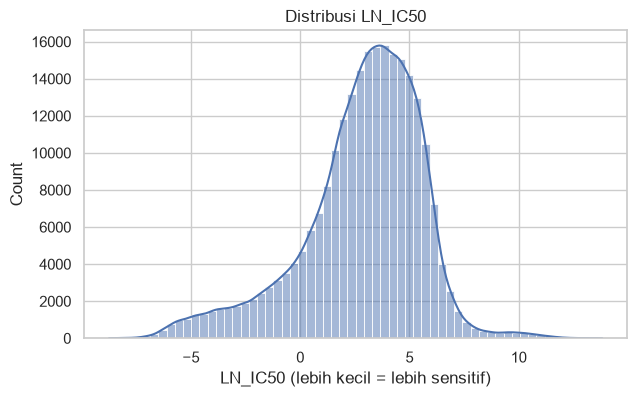

In [13]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(gdsc["LN_IC50"], bins=60, kde=True, ax=ax)
ax.set_title("Distribusi LN_IC50")
ax.set_xlabel("LN_IC50 (lebih kecil = lebih sensitif)")
plt.show()              # 11.542

### Grafik Boxplot `LN_IC50` per jaringan

melihat apakah karakter biologis sel berkaitan dengan respon obat. jaringan diurutkan berdasarkan median agar peringkat mudah dibaca.

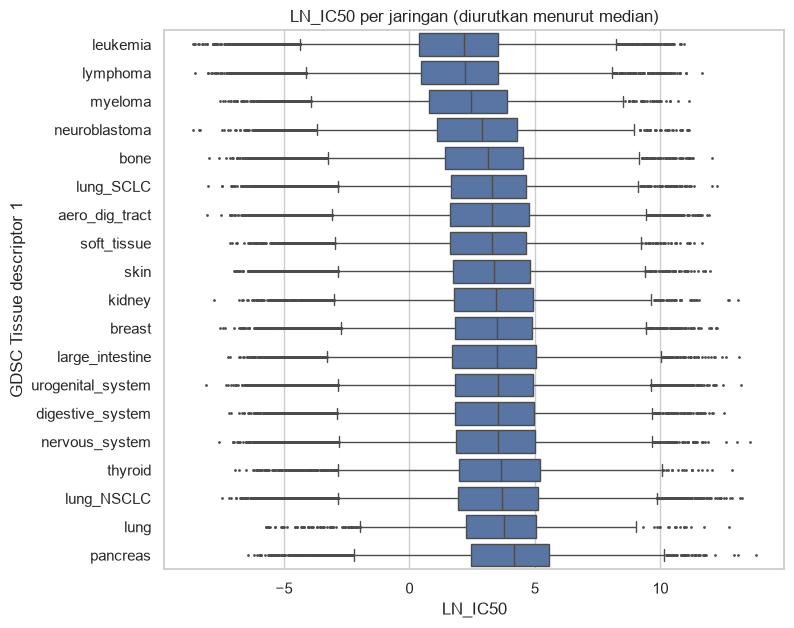

In [14]:
urutan = gdsc.groupby("GDSC Tissue descriptor 1")["LN_IC50"].median().sort_values().index
fig, ax = plt.subplots(figsize=(8, 7))
sns.boxplot(data=gdsc, y="GDSC Tissue descriptor 1", x="LN_IC50",
            order=urutan, fliersize=1, ax=ax)
ax.set_title("LN_IC50 per jaringan (diurutkan menurut median)")
plt.show()

### Grafik Scatter plot `LN_IC50` VS `AUC`

dengan dua kolom ini `LN_IC50` VS `AUC` mengukur sensitivitas dengan cara berbeda, apakah keduanya menceritakan hal yang sama.Dipakai sampel acak 20.000 baris agar grafik tidak terlalu padat dan berat, dan titik dibuat transparan agar area yang padat terlihat.

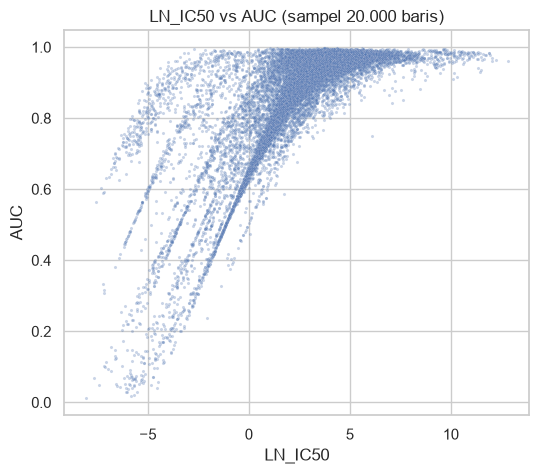

In [15]:
s = gdsc.sample(20000, random_state=42)             # sampel supaya grafik tidak berat
fig, ax = plt.subplots(figsize=(6, 5))
sns.scatterplot(data=s, x="LN_IC50", y="AUC", s=5, alpha=0.3, ax=ax)
ax.set_title("LN_IC50 vs AUC (sampel 20.000 baris)")
plt.show()

### Grafik Histogram TPM sebelum dan sesudah `log2(TPM+1)`

grafik ini berguna untuk bukti keputusan transformasi di rencana preprocessing. Dua histogram disandingkan agar sebelum dan sesudah log bisa dibandingkan langsung.Dipakai sampel acak 500.000 nilai dari 100 sampel, karena seluruh matriks berisi sekitar 59 juta nilai.

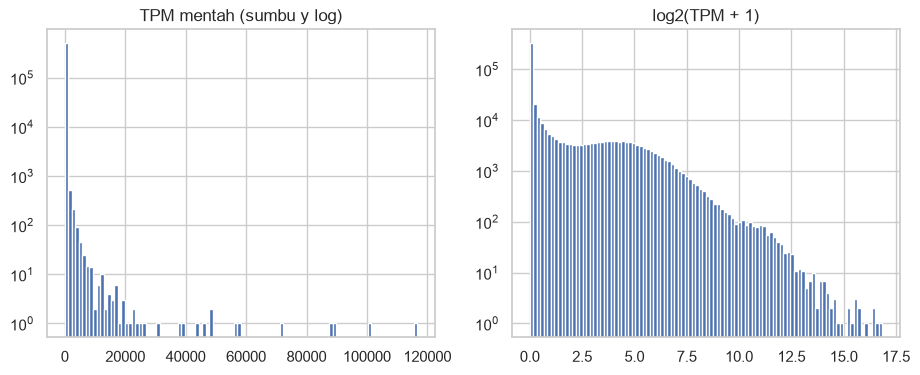

Persentase nilai 0: 54.2 %


In [16]:
kol = rng.choice(expr.columns, size=100, replace=False)
nilai = expr[kol].to_numpy().ravel()
nilai = rng.choice(nilai, size=500_000, replace=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(nilai, bins=100, log=True);                axes[0].set_title("TPM mentah (sumbu y log)")
axes[1].hist(np.log2(nilai + 1), bins=100, log=True);   axes[1].set_title("log2(TPM + 1)")
plt.show()
print("Persentase nilai 0:", round(100 * (nilai == 0).mean(), 1), "%")

### Grafik Histogram proporsi sampel aktif per gen

gen dianggap **aktif** pada suatu sampel bila TPM-nya lebih dari 1. Untuk tiap gen dihitung proporsi sampel tempat ia aktif (0 berarti tidak pernah aktif, 1 berarti aktif di semua sampel), lalu sebarannya digambar dengan histogram.

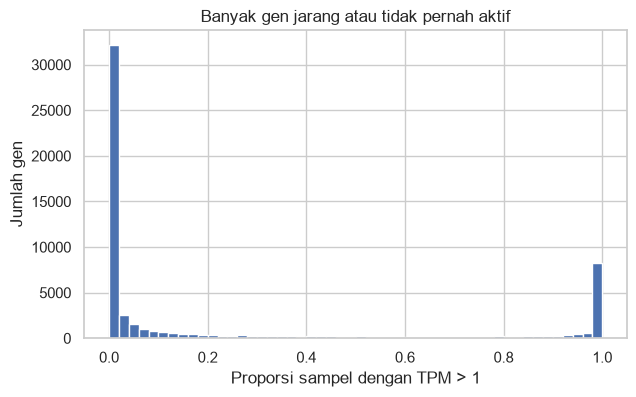

In [17]:
gen_aktif = (expr > 1).mean(axis=1)     # proporsi sampel dengan TPM > 1 untuk tiap gen
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(gen_aktif, bins=50)
ax.set_xlabel("Proporsi sampel dengan TPM > 1"); ax.set_ylabel("Jumlah gen")
ax.set_title("Banyak gen jarang atau tidak pernah aktif")
plt.show()

# Data Quality Findings

Tiap temuan dibuktikan dengan kode, lalu dirangkum dalam satu tabel di akhir bagian ini.

## Temuan 1. Missing value pada metadata GDSC bersifat berkelompok, bukan acak


In [18]:
kolom_meta = ["GDSC Tissue descriptor 1", "GDSC Tissue descriptor 2", "Screen Medium",
              "Growth Properties", "CNA", "Gene Expression", "Methylation"]

print("Jumlah baris kosong per kolom metadata:")
print(gdsc[kolom_meta].isna().sum().to_string())

# apakah ketujuh kolom itu kosong di baris yang sama?
kosong_semua = gdsc[kolom_meta].isna().all(axis=1)
kosong_sebagian = gdsc[kolom_meta].isna().any(axis=1) & ~kosong_semua
print("\nBaris dengan 7 kolom kosong sekaligus:", kosong_semua.sum(), f"({kosong_semua.mean():.2%} dari seluruh baris)")
print("Baris dengan hanya sebagian kolom yang kosong:", kosong_sebagian.sum())

tanpa_meta = gdsc[kosong_semua]
print("\nJumlah cell line yang terdampak:", tanpa_meta.COSMIC_ID.nunique(), "dari", gdsc.COSMIC_ID.nunique())
print("Contoh:", tanpa_meta.CELL_LINE_NAME.drop_duplicates().head(8).tolist())

# apakah Cancer Type dan MSI ikut kosong di baris yang sama?
print("\nDi baris itu, Cancer Type dan MSI kosong semua?")
print(tanpa_meta[["Cancer Type (matching TCGA label)", "Microsatellite instability Status (MSI)"]].isna().all().to_string())

Jumlah baris kosong per kolom metadata:
GDSC Tissue descriptor 1    9366
GDSC Tissue descriptor 2    9366
Screen Medium               9366
Growth Properties           9366
CNA                         9366
Gene Expression             9366
Methylation                 9366

Baris dengan 7 kolom kosong sekaligus: 9366 (3.87% dari seluruh baris)
Baris dengan hanya sebagian kolom yang kosong: 0

Jumlah cell line yang terdampak: 39 dari 969
Contoh: ['5637', 'T24', '697', 'HuTu-80', 'SNU-1', 'SNU-5', 'SNU-16', 'NTERA-2-cl-D1']

Di baris itu, Cancer Type dan MSI kosong semua?
Cancer Type (matching TCGA label)          True
Microsatellite instability Status (MSI)    True


## Temuan 2. Duplikasi tersembunyi pada obat

Cek duplikat biasa memakai `DRUG_ID` tidak menemukan apa-apa. Di sini kami bandingkan dengan memakai `DRUG_NAME`.

In [19]:
print("Duplikat baris penuh:", gdsc.duplicated().sum())
print("Duplikat (COSMIC_ID, DRUG_ID):  ", gdsc.duplicated(["COSMIC_ID", "DRUG_ID"]).sum())
print("Duplikat (COSMIC_ID, DRUG_NAME):", gdsc.duplicated(["COSMIC_ID", "DRUG_NAME"]).sum())
print("DRUG_ID unik:", gdsc.DRUG_ID.nunique(), "| DRUG_NAME unik:", gdsc.DRUG_NAME.nunique())

# obat yang punya lebih dari satu DRUG_ID
id_per_nama = gdsc.groupby("DRUG_NAME").DRUG_ID.nunique()
obat_ganda = id_per_nama[id_per_nama > 1].index.tolist()
print("\nObat dengan lebih dari satu DRUG_ID:", obat_ganda)

# apakah hasil kedua ID sama untuk cell line yang sama?
hasil = []
for nama in obat_ganda:
    g = gdsc[gdsc.DRUG_NAME == nama]
    id1, id2 = sorted(g.DRUG_ID.unique())
    p = g.pivot_table(index="COSMIC_ID", columns="DRUG_ID", values="LN_IC50").dropna()
    hasil.append({"obat": nama, "ID_1": id1, "ID_2": id2, "sel_diuji_di_keduanya": len(p),
                  "korelasi": round(p[id1].corr(p[id2]), 2),
                  "rata2_selisih (ID_2 - ID_1)": round((p[id2] - p[id1]).mean(), 2)})
display(pd.DataFrame(hasil))

dup = gdsc[gdsc.duplicated(["COSMIC_ID", "DRUG_NAME"], keep=False)]
selisih = dup.groupby(["COSMIC_ID", "DRUG_NAME"]).LN_IC50.agg(lambda s: s.max() - s.min())
print("Selisih LN_IC50 pada pasangan ganda: median", round(selisih.median(), 2),
      "| lebih dari 1 satuan:", f"{(selisih > 1).mean():.0%}")

# spasi tersembunyi pada nama obat
spasi = gdsc.DRUG_NAME != gdsc.DRUG_NAME.str.strip()
print("\nBaris dengan spasi di ujung nama obat:", spasi.sum(), "->", gdsc.DRUG_NAME[spasi].map(repr).unique().tolist())

Duplikat baris penuh: 0
Duplikat (COSMIC_ID, DRUG_ID):   0
Duplikat (COSMIC_ID, DRUG_NAME): 6288
DRUG_ID unik: 295 | DRUG_NAME unik: 286

Obat dengan lebih dari satu DRUG_ID: ['Acetalax', 'Dactinomycin', 'Docetaxel', 'Fulvestrant', 'GSK343', 'Oxaliplatin', 'Selumetinib', 'Ulixertinib', 'Uprosertib']


,obat,ID_1,ID_2,sel_diuji_di_keduanya,korelasi,rata2_selisih (ID_2 - ID_1)
0,Acetalax,1803,1804,717,0.93,-0.38
1,Dactinomycin,1811,1911,699,0.73,-2.37
2,Docetaxel,1007,1819,669,0.83,2.22
3,Fulvestrant,1200,1816,715,0.65,1.57
4,GSK343,1627,2037,669,0.57,1.56
5,Oxaliplatin,1089,1806,717,0.88,1.08
6,Selumetinib,1062,1736,699,0.84,0.55
7,Ulixertinib,1908,2047,735,0.57,-0.55
8,Uprosertib,1553,2106,668,0.79,-0.12


Selisih LN_IC50 pada pasangan ganda: median 1.1 | lebih dari 1 satuan: 54%

Baris dengan spasi di ujung nama obat: 739 -> ["'GSK-LSD1-2HCl '"]


## Temuan 3. Ketidakkonsistenan identitas antar sumber

GDSC dan CCLE ditulis dengan format nama yang berbeda (mis. `A549` di GDSC, `A549_LUNG` di CCLE). Di sini kami cek seberapa jauh perbedaannya.

In [20]:
def norm(s):
    # huruf besar, buang semua tanda baca
    return re.sub(r"[^A-Z0-9]", "", str(s).upper())

cl_gdsc = gdsc.drop_duplicates("COSMIC_ID")[["COSMIC_ID", "CELL_LINE_NAME", "GDSC Tissue descriptor 1"]].copy()
cl_gdsc["key"] = cl_gdsc.CELL_LINE_NAME.map(norm)

cl_ccle = pd.DataFrame({"ccle_sample": expr.columns})
cl_ccle["nama"] = cl_ccle.ccle_sample.str.split("_", n=1).str[0]
cl_ccle["jaringan"] = cl_ccle.ccle_sample.str.split("_", n=1).str[1]
cl_ccle["key"] = cl_ccle.nama.map(norm)

print("Cell line GDSC:", len(cl_gdsc), "| sampel CCLE:", len(cl_ccle))
print("Nama cocok persis (tanpa normalisasi):", len(set(cl_gdsc.CELL_LINE_NAME) & set(cl_ccle.nama)))
print("Pasangan setelah nama dinormalisasi:  ", len(cl_gdsc.merge(cl_ccle, on="key")))

# dua cell line berbeda bisa jadi bernama sama setelah tanda baca dibuang
print("\nKunci ganda di GDSC:")
display(cl_gdsc[cl_gdsc.key.duplicated(keep=False)][["CELL_LINE_NAME", "GDSC Tissue descriptor 1", "key"]])
print("Kunci ganda di CCLE:")
display(cl_ccle[cl_ccle.key.duplicated(keep=False)][["ccle_sample", "key"]])

# pasangan yang sebenarnya sama tetapi tidak cocok (huruf O vs angka 0)
print("Beda huruf O dan angka 0:",
      cl_gdsc.CELL_LINE_NAME[cl_gdsc.CELL_LINE_NAME.isin(["786-0", "U031"])].tolist(), "vs",
      cl_ccle.ccle_sample[cl_ccle.nama.isin(["786O", "UO31"])].tolist())

# istilah jaringan dan ID gen
print("\nKategori jaringan: GDSC =", cl_gdsc["GDSC Tissue descriptor 1"].nunique(), "| CCLE =", cl_ccle.jaringan.nunique())
print("Contoh gene_id CCLE:", expr.index[:3].tolist(), "(kode Ensembl bernomor versi, tanpa nama gen)")

Cell line GDSC: 969 | sampel CCLE: 1019
Nama cocok persis (tanpa normalisasi): 126
Pasangan setelah nama dinormalisasi:   622

Kunci ganda di GDSC:


,CELL_LINE_NAME,GDSC Tissue descriptor 1,key
527,KM-H2,lymphoma,KMH2
642,TT,thyroid,TT
821,KMH-2,thyroid,KMH2
859,T-T,aero_dig_tract,TT


Kunci ganda di CCLE:


,ccle_sample,key
976,TT_OESOPHAGUS,TT
977,TT_THYROID,TT


Beda huruf O dan angka 0: ['786-0', 'U031'] vs ['786O_KIDNEY', 'UO31_KIDNEY']

Kategori jaringan: GDSC = 19 | CCLE = 26
Contoh gene_id CCLE: ['ENSG00000000003.10', 'ENSG00000000005.5', 'ENSG00000000419.8'] (kode Ensembl bernomor versi, tanpa nama gen)


## Temuan 4. Data berkurang dan ada bias seleksi setelah penggabungan

Temuan ini baru bisa dihitung setelah GDSC dan CCLE digabung, jadi kode buktinya ada di **Bagian bukti temuan 4** (setelah pipeline).

## Temuan 5. Ekspresi gen sangat miring, sarat nol, dan punya nilai ekstrem

In [21]:
nilai = expr.to_numpy()
print("Jumlah gen:", expr.shape[0], "| jumlah sampel:", expr.shape[1])
print("NaN:", np.isnan(nilai).sum(), "| nilai negatif:", (nilai < 0).sum())

# banyak nol
print(f"\nNilai tepat 0: {(nilai == 0).mean():.1%}")
print("Gen yang nol di semua sampel:", (expr.sum(axis=1) == 0).sum())
print("Gen yang tidak pernah di atas TPM 1:", (expr.max(axis=1) <= 1).sum())

# sebaran miring dan nilai ekstrem
print("\nMedian:", np.median(nilai), "| rata-rata:", nilai.mean().round(1))
print("Persentil 99:", np.percentile(nilai, 99).round(1), "| persentil 99,9:", np.percentile(nilai, 99.9).round(1),
      "| maksimum:", nilai.max())
print("Sel dengan nilai > 100.000 TPM:", (nilai > 100000).sum())

def skewness_penuh(df, f=lambda x: x, blok=100):
    """Skewness seluruh nilai matriks (tanpa pengacakan), dihitung per blok kolom agar hemat memori."""
    n = df.size
    m = sum(f(df.iloc[:, j:j+blok].to_numpy("float64")).sum() for j in range(0, df.shape[1], blok)) / n
    m2 = m3 = 0.0
    for j in range(0, df.shape[1], blok):
        d = f(df.iloc[:, j:j+blok].to_numpy("float64")) - m
        m2 += (d**2).sum(); m3 += (d**3).sum()
    return (m3 / n) / (m2 / n) ** 1.5

skew_mentah = skewness_penuh(expr)
skew_log = skewness_penuh(expr, lambda x: np.log2(x + 1))
print("Skewness seluruh matriks TPM: data asli =", round(skew_mentah, 1),
      "| setelah log2(TPM+1) =", round(skew_log, 2))

# satu gen yang mendominasi
gen_puncak = expr.idxmax()
print("\nGen tertinggi di tiap sampel (3 teratas):", gen_puncak.value_counts().head(3).to_dict())
porsi = expr.max() / expr.sum() * 100
print("Porsi total TPM milik gen teratas per sampel: median", round(porsi.median(), 1), "% | maksimum", round(porsi.max(), 1), "%")

Jumlah gen: 57820 | jumlah sampel: 1019
NaN: 0 | nilai negatif: 0

Nilai tepat 0: 54.4%
Gen yang nol di semua sampel: 8444
Gen yang tidak pernah di atas TPM 1: 18737

Median: 0.0 | rata-rata: 17.3
Persentil 99: 206.4 | persentil 99,9: 2222.4 | maksimum: 225730.0
Sel dengan nilai > 100.000 TPM: 70
Skewness seluruh matriks TPM: data asli = 149.5 | setelah log2(TPM+1) = 2.06

Gen tertinggi di tiap sampel (3 teratas): {'ENSG00000228253.1': 971, 'ENSG00000198712.1': 7, 'ENSG00000156508.13': 6}
Porsi total TPM milik gen teratas per sampel: median 4.8 % | maksimum 22.6 %


## Temuan 6. Kategori tidak seimbang dan label tidak lengkap

In [22]:
cl = gdsc.drop_duplicates("COSMIC_ID")

# jaringan GDSC
jar = cl["GDSC Tissue descriptor 1"].value_counts()
print("GDSC Tissue descriptor 1 (jumlah cell line per kategori):")
print(cl["GDSC Tissue descriptor 1"].value_counts(dropna=False).to_string())
print("\nKategori terbesar:", jar.index[0], jar.iloc[0], "| terkecil:", jar.index[-1], jar.iloc[-1],
      "| rasio:", round(jar.iloc[0] / jar.iloc[-1], 1))
print("Kategori dengan kurang dari 20 cell line:", (jar < 20).sum())

# label TCGA
print("\nTCGA_DESC: UNCLASSIFIED =", (cl.TCGA_DESC == "UNCLASSIFIED").sum(), "| kosong =", cl.TCGA_DESC.isna().sum())
ct = cl["Cancer Type (matching TCGA label)"]
print("Cancer Type: kosong =", ct.isna().sum(), f"({ct.isna().mean():.1%} dari cell line)")
print("MSI:", cl["Microsatellite instability Status (MSI)"].value_counts(dropna=False).to_dict())

# jaringan CCLE (dari nama sampel)
jar_ccle = cl_ccle.jaringan.value_counts()
print("\nJaringan CCLE: terbesar =", jar_ccle.index[0], jar_ccle.iloc[0],
      "| terkecil =", jar_ccle.index[-1], jar_ccle.iloc[-1])
print("Kategori CCLE dengan kurang dari 10 sampel:", (jar_ccle < 10).sum(), "dari", len(jar_ccle))

GDSC Tissue descriptor 1 (jumlah cell line per kategori):
GDSC Tissue descriptor 1
lung_NSCLC           107
urogenital_system    101
leukemia              81
aero_dig_tract        74
lymphoma              67
lung_SCLC             60
skin                  54
nervous_system        54
breast                52
large_intestine       46
digestive_system      42
NaN                   39
bone                  38
kidney                34
neuroblastoma         32
pancreas              29
soft_tissue           20
myeloma               17
thyroid               15
lung                   7

Kategori terbesar: lung_NSCLC 107 | terkecil: lung 7 | rasio: 15.3
Kategori dengan kurang dari 20 cell line: 3

TCGA_DESC: UNCLASSIFIED = 181 | kosong = 6
Cancer Type: kosong = 205 (21.2% dari cell line)
MSI: {'MSS/MSI-L': 858, 'MSI-H': 58, nan: 53}

Jaringan CCLE: terbesar = LUNG 188 | terkecil = SMALL_INTESTINE 1
Kategori CCLE dengan kurang dari 10 sampel: 6 dari 26


In [23]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.decomposition import PCA
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

In [24]:
print("Skewness TPM (seluruh matriks): mentah =", round(skew_mentah, 1),
      "| setelah log2(TPM+1) =", round(skew_log, 2)) 

Skewness TPM (seluruh matriks): mentah = 149.5 | setelah log2(TPM+1) = 2.06


# PREPROCESSING

## 1.1 Penataan Struktur Data

In [25]:
info_sampel = pd.DataFrame({"kolom_ccle": expr.columns})
info_sampel["nama_sel"]    = info_sampel["kolom_ccle"].str.split("_").str[0]
info_sampel["tissue_ccle"] = info_sampel["kolom_ccle"].str.split("_", n=1).str[1]
info_sampel = info_sampel.set_index("kolom_ccle")
print("Sampel:", len(info_sampel), "| jaringan:", info_sampel["tissue_ccle"].nunique())

AMBANG_TPM, AMBANG_SAMPEL = 1, 0.10
lolos  = (expr > AMBANG_TPM).mean(axis=1) >= AMBANG_SAMPEL
expr_f = expr.loc[lolos]
print(f"Gen: {expr.shape[0]:,} -> {expr_f.shape[0]:,} ({lolos.mean()*100:.1f}% dipertahankan)")
print(f"Proporsi nilai 0: {(expr == 0).to_numpy().mean()*100:.1f}% -> {(expr_f == 0).to_numpy().mean()*100:.1f}%")

# --- GDSC: duplikasi pasangan cell line-obat ---
print("\nDuplikat (COSMIC_ID, DRUG_ID)  :", gdsc.duplicated(["COSMIC_ID", "DRUG_ID"]).sum())
print("Duplikat (COSMIC_ID, DRUG_NAME):", gdsc.duplicated(["COSMIC_ID", "DRUG_NAME"]).sum())
gdsc["DRUG_NAME"] = gdsc["DRUG_NAME"].str.strip()
resp = (gdsc.groupby(["COSMIC_ID", "DRUG_NAME"], as_index=False)
            .agg(LN_IC50=("LN_IC50", "mean"), AUC=("AUC", "mean"), Z_SCORE=("Z_SCORE", "mean"),
                 TARGET_PATHWAY=("TARGET_PATHWAY", "first")))
print("Baris GDSC:", gdsc.shape[0], "->", resp.shape[0])

Sampel: 1019 | jaringan: 26
Gen: 57,820 -> 19,809 (34.3% dipertahankan)
Proporsi nilai 0: 54.4% -> 5.4%

Duplikat (COSMIC_ID, DRUG_ID)  : 0
Duplikat (COSMIC_ID, DRUG_NAME): 6288
Baris GDSC: 242035 -> 235747


## 1.2 *Missing Value*

In [26]:
# --- matriks respons ---
mat_resp = resp.pivot(index="COSMIC_ID", columns="DRUG_NAME", values="LN_IC50")
print("Matriks awal:", mat_resp.shape, f"| kosong {mat_resp.isna().mean().mean()*100:.1f}%")

BATAS_KOSONG = 0.50
kosong_sel, kosong_obat = mat_resp.isna().mean(axis=1), mat_resp.isna().mean(axis=0)
mat_resp = mat_resp.loc[kosong_sel[kosong_sel <= BATAS_KOSONG].index,
                        kosong_obat[kosong_obat <= BATAS_KOSONG].index]
print("Matriks akhir:", mat_resp.shape, f"| kosong {mat_resp.isna().mean().mean()*100:.1f}%")

# --- metadata GDSC: satu baris per cell line (alias) ---
nama_ringkas = {"GDSC Tissue descriptor 1": "tissue", "GDSC Tissue descriptor 2": "tissue2",
                "Microsatellite instability Status (MSI)": "msi", "Growth Properties": "growth",
                "Screen Medium": "medium", "TCGA_DESC": "tcga_desc",
                "Cancer Type (matching TCGA label)": "tcga_label"}

meta = (gdsc.drop_duplicates("COSMIC_ID")[["COSMIC_ID", "CELL_LINE_NAME"] + list(nama_ringkas)]
            .rename(columns=nama_ringkas).set_index("COSMIC_ID"))
display(pd.DataFrame({"jumlah_kosong": meta.isna().sum(), "persen": (meta.isna().mean() * 100).round(2)}))

meta_bersih = meta.drop(columns="tcga_label").copy()
for k in ["tissue", "tissue2", "msi", "growth", "medium", "tcga_desc"]:
    meta_bersih[k] = meta_bersih[k].fillna("Unknown")
print("Nilai kosong tersisa pada metadata:", int(meta_bersih.isna().sum().sum()))

Matriks awal: (969, 286) | kosong 14.9%
Matriks akhir: (965, 270) | kosong 11.2%


,jumlah_kosong,persen
CELL_LINE_NAME,0,0.00
tissue,39,4.02
tissue2,39,4.02
msi,53,5.47
growth,39,4.02
medium,39,4.02
tcga_desc,6,0.62
tcga_label,205,21.16


Nilai kosong tersisa pada metadata: 0


## 1.3 *Outlier*

In [27]:
# --- (a) transformasi log ---
expr_log = np.log2(expr_f + 1)
gen_maks = expr_f.max(axis=1).idxmax()
print(f"TPM maks {expr_f.loc[gen_maks].max():,.0f} ({gen_maks}) -> log2(TPM+1) = {expr_log.loc[gen_maks].max():.2f}")

# --- (b) QC sampel (tandai, tidak dibuang) ---
total_tpm       = expr.sum(axis=0)
n_terdeteksi    = (expr > AMBANG_TPM).sum(axis=0)
korelasi_median = expr_log.corrwith(expr_log.median(axis=1))
qc = pd.DataFrame({"total_tpm": total_tpm, "n_gen_terdeteksi": n_terdeteksi,
                   "korelasi_ke_median": korelasi_median}).join(info_sampel["tissue_ccle"])
display(qc[["total_tpm", "n_gen_terdeteksi", "korelasi_ke_median"]].describe().round(3))

mad    = (korelasi_median - korelasi_median.median()).abs().median()
ambang = korelasi_median.median() - 3 * 1.4826 * mad
ditandai = qc[qc["korelasi_ke_median"] < ambang].sort_values("korelasi_ke_median")
print(f"Ambang korelasi: {ambang:.3f} | sampel ditandai: {len(ditandai)}")
display(ditandai.round(3))
del expr_f  # membebaskan memori; analisis selanjutnya memakai expr_log

# --- (c) nilai ekstrem LN_IC50: global vs per obat ---
def batas_iqr(s):
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

lo, hi = batas_iqr(resp["LN_IC50"])
ekstrem_global   = (resp["LN_IC50"] < lo) | (resp["LN_IC50"] > hi)
ekstrem_per_obat = resp.groupby("DRUG_NAME")["LN_IC50"].transform(
    lambda g: (g < batas_iqr(g)[0]) | (g > batas_iqr(g)[1])).astype(bool)
print(f"\nEkstrem global   : {ekstrem_global.sum():>6} ({ekstrem_global.mean()*100:.1f}%)")
print(f"Ekstrem per obat : {ekstrem_per_obat.sum():>6} ({ekstrem_per_obat.mean()*100:.1f}%)")
print(f"Ditandai global tetapi tidak ekstrem pada obatnya: {(ekstrem_global & ~ekstrem_per_obat).sum()} "
      f"({(ekstrem_global & ~ekstrem_per_obat).sum()/ekstrem_global.sum()*100:.1f}% dari yang ditandai global)")

TPM maks 225,730 (ENSG00000228253.1) -> log2(TPM+1) = 17.78


,total_tpm,n_gen_terdeteksi,korelasi_ke_median
count,1019.000,1019.000,1019.000
mean,1000000.118,14344.201,0.889
std,1.174,865.155,0.027
min,999994.630,11578.000,0.801
25%,999999.470,13793.000,0.872
50%,1000000.110,14281.000,0.895
75%,1000000.800,14849.500,0.909
max,1000006.030,17738.000,0.942


Ambang korelasi: 0.816 | sampel ditandai: 4


,total_tpm,n_gen_terdeteksi,korelasi_ke_median,tissue_ccle
NCIH1385_LUNG,999999.62,15745,0.801,LUNG
TT_THYROID,1000000.54,17217,0.806,THYROID
DAUDI_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,1000001.03,13840,0.810,HAEMATOPOIETIC_AND_LYMPHOID_TISSUE
CA46_HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,1000000.40,14863,0.813,HAEMATOPOIETIC_AND_LYMPHOID_TISSUE



Ekstrem global   :  10823 (4.6%)
Ekstrem per obat :   4037 (1.7%)
Ditandai global tetapi tidak ekstrem pada obatnya: 10428 (96.4% dari yang ditandai global)


## 1.4 Data Kategorikal

In [28]:
def gabung_kategori_jarang(s, ambang_persen=1.0, label="OTHER", abaikan=("Unknown",)):
    persen = s.value_counts(normalize=True) * 100
    langka = persen[(persen < ambang_persen) & (~persen.index.isin(abaikan))].index
    return s.where(~s.isin(langka), label), list(langka)

info_sampel["tissue_major"], langka = gabung_kategori_jarang(info_sampel["tissue_ccle"])
info_sampel["hemato"] = info_sampel["tissue_ccle"].eq("HAEMATOPOIETIC_AND_LYMPHOID_TISSUE")
print("Digabung ke OTHER:", langka)
print("Jumlah kategori jaringan:", info_sampel["tissue_ccle"].nunique(), "->", info_sampel["tissue_major"].nunique())

for k in ["tissue", "msi", "growth", "medium"]:
    meta_bersih[k], _ = gabung_kategori_jarang(meta_bersih[k], label="Other")
print("\nKategori tissue GDSC setelah penggabungan:")
display(meta_bersih["tissue"].value_counts().to_frame("jumlah_sel").T)

Digabung ke OTHER: ['PLEURA', 'PROSTATE', 'BILIARY_TRACT', 'CERVIX', 'SALIVARY_GLAND', 'SMALL_INTESTINE']
Jumlah kategori jaringan: 26 -> 21

Kategori tissue GDSC setelah penggabungan:


tissue,lung_NSCLC,urogenital_system,leukemia,aero_dig_tract,lymphoma,lung_SCLC,skin,nervous_system,breast,large_intestine,digestive_system,Unknown,bone,kidney,neuroblastoma,pancreas,soft_tissue,myeloma,thyroid,Other
jumlah_sel,107,101,81,74,67,60,54,54,52,46,42,39,38,34,32,29,20,17,15,7


## 1.5 Perbedaan Skala

In [29]:
# --- ekspresi: seleksi gen berbasis varians + standardisasi ---
X_log = expr_log.T
X_log.index.name = "kolom_ccle"
N_GEN   = 2000
var_gen = X_log.var(axis=0).sort_values(ascending=False)
X_top   = X_log[var_gen.index[:N_GEN]]
print(f"Varians gen peringkat 1: {var_gen.iloc[0]:.2f} | peringkat {N_GEN}: {var_gen.iloc[N_GEN-1]:.2f} | terakhir: {var_gen.iloc[-1]:.2f}")

X_std = pd.DataFrame(StandardScaler().fit_transform(X_top), index=X_top.index, columns=X_top.columns)
print("Setelah standardisasi -> rata-rata:", round(float(X_std.mean().mean()), 3), "| simpangan baku:", round(float(X_std.std().mean()), 3))

# --- respons: skala antar obat dan z-score per obat ---
median_obat = mat_resp.median()
print(f"\nMedian LN_IC50 per obat: {median_obat.min():.2f} sampai {median_obat.max():.2f} | std antar median: {median_obat.std():.2f}")
print(f"Median std di dalam obat: {mat_resp.std().median():.2f}")
z_resp = (mat_resp - mat_resp.mean()) / mat_resp.std()

Varians gen peringkat 1: 15.96 | peringkat 2000: 2.72 | terakhir: 0.08
Setelah standardisasi -> rata-rata: -0.0 | simpangan baku: 1.0

Median LN_IC50 per obat: -5.39 sampai 10.42 | std antar median: 2.40
Median std di dalam obat: 1.36


## 1.6 Penyatuan GDSC dan CCLE

In [30]:
H = "HAEMATOPOIETIC_AND_LYMPHOID_TISSUE"
# Jaringan GDSC -> jaringan CCLE yang masuk akal. Dipakai hanya untuk menyelesaikan kunci ambigu
# dan menandai pasangan yang janggal.
KOMPAT = {
    "aero_dig_tract": {"UPPER_AERODIGESTIVE_TRACT", "OESOPHAGUS", "SALIVARY_GLAND"},
    "bone": {"BONE", "SOFT_TISSUE"}, "breast": {"BREAST"},
    "digestive_system": {"STOMACH", "LIVER", "BILIARY_TRACT", "SMALL_INTESTINE", "PANCREAS", "LARGE_INTESTINE", "OESOPHAGUS"},
    "kidney": {"KIDNEY"}, "large_intestine": {"LARGE_INTESTINE"},
    "leukemia": {H}, "lymphoma": {H}, "myeloma": {H},
    "lung": {"LUNG", "PLEURA"}, "lung_NSCLC": {"LUNG", "PLEURA"}, "lung_SCLC": {"LUNG", "PLEURA"},
    "nervous_system": {"CENTRAL_NERVOUS_SYSTEM"}, "neuroblastoma": {"AUTONOMIC_GANGLIA"},
    "pancreas": {"PANCREAS"}, "skin": {"SKIN"}, "soft_tissue": {"SOFT_TISSUE", "BONE"},
    "thyroid": {"THYROID"},
    "urogenital_system": {"OVARY", "ENDOMETRIUM", "URINARY_TRACT", "PROSTATE", "CERVIX", "KIDNEY", "SOFT_TISSUE"},
}
# Pasangan sah yang terlewat normalisasi (huruf O vs angka 0). Ditambahkan manual.
MANUAL = {"786-0": "786O_KIDNEY", "U031": "UO31_KIDNEY"}

def pemetaan_cell_line(gdsc, ccle_samples):
    """Memetakan cell line GDSC ke sampel CCLE secara 1:1. Ini SATU-SATUNYA implementasi pencocokan
    di notebook (dipakai ulang oleh Initial Data Pipeline).
    Urutan: nama ternormalisasi yang unik -> kunci ambigu diselesaikan dengan kesesuaian jaringan -> pemetaan manual."""
    cells = (gdsc.drop_duplicates("COSMIC_ID")[["COSMIC_ID", "CELL_LINE_NAME", "GDSC Tissue descriptor 1"]]
                 .rename(columns={"GDSC Tissue descriptor 1": "tissue_gdsc"}))
    cells["key"] = cells.CELL_LINE_NAME.map(norm)
    ccle = pd.DataFrame({"ccle_sample": list(ccle_samples)})
    ccle["key"] = ccle.ccle_sample.str.split("_", n=1).str[0].map(norm)
    ccle["tissue_ccle"] = ccle.ccle_sample.str.split("_", n=1).str[1]
    jaringan_cocok = lambda a, b: a in KOMPAT and b in KOMPAT[a]

    kand = cells.merge(ccle, on="key")
    kand["ambigu"] = ((kand.groupby("key").COSMIC_ID.transform("nunique") > 1) |
                      (kand.groupby("key").ccle_sample.transform("nunique") > 1))
    kand["tissue_cocok"] = [jaringan_cocok(a, b) for a, b in zip(kand.tissue_gdsc, kand.tissue_ccle)]
    unik    = kand[~kand.ambigu].assign(metode="nama_unik")
    selesai = kand[kand.ambigu & kand.tissue_cocok].assign(metode="nama+jaringan")
    manual  = pd.DataFrame([
        {"COSMIC_ID": r.COSMIC_ID, "CELL_LINE_NAME": r.CELL_LINE_NAME, "tissue_gdsc": r.tissue_gdsc, "key": r.key,
         "ccle_sample": c, "tissue_ccle": c.split("_", 1)[1], "metode": "manual"}
        for n, c in MANUAL.items() for r in cells[cells.CELL_LINE_NAME == n].itertuples()])
    peta = pd.concat([unik, selesai, manual], ignore_index=True).drop(columns=["ambigu", "tissue_cocok"])
    peta["tissue_cocok"] = [jaringan_cocok(a, b) for a, b in zip(peta.tissue_gdsc, peta.tissue_ccle)]
    assert peta.COSMIC_ID.is_unique and peta.ccle_sample.is_unique, "pemetaan tidak 1:1"
    ringkasan = dict(kandidat=len(kand), ambigu=int(kand.ambigu.sum()), nama_unik=len(unik),
                     nama_jaringan=len(selesai), manual=len(manual), total=len(peta))
    return peta, ringkasan

peta_plan, ringkasan = pemetaan_cell_line(gdsc, info_sampel.index)
print("Ringkasan pencocokan:", ringkasan)

cocok = peta_plan.rename(columns={"ccle_sample": "kolom_ccle"})[["COSMIC_ID", "kolom_ccle", "metode"]]
n_gdsc = gdsc.COSMIC_ID.nunique()
print(f"Sel GDSC: {n_gdsc} | berhasil dicocokkan: {len(cocok)} ({len(cocok)/n_gdsc*100:.1f}%)")

info_sampel = (info_sampel.drop(columns=["COSMIC_ID", "ada_respons"], errors="ignore")   # agar sel aman dijalankan ulang
               .join(cocok.set_index("kolom_ccle")[["COSMIC_ID"]]))
info_sampel["ada_respons"] = info_sampel["COSMIC_ID"].isin(mat_resp.index)
print("Sampel CCLE dengan data respons yang lolos ambang:", int(info_sampel["ada_respons"].sum()), "dari", len(info_sampel))

Ringkasan pencocokan: {'kandidat': 622, 'ambigu': 6, 'nama_unik': 616, 'nama_jaringan': 3, 'manual': 2, 'total': 621}
Sel GDSC: 969 | berhasil dicocokkan: 621 (64.1%)
Sampel CCLE dengan data respons yang lolos ambang: 618 dari 1019


## 1.7 *Data Leakage*

In [31]:
class PilihGenVarians(BaseEstimator, TransformerMixin):
    """Memilih n_gen gen dengan varians terbesar; dihitung hanya dari data yang diberikan ke fit()."""
    def __init__(self, n_gen=2000):
        self.n_gen = n_gen
    def fit(self, X, y=None):
        self.idx_ = np.argsort(np.asarray(X).var(axis=0))[::-1][: self.n_gen]
        return self
    def transform(self, X):
        return np.asarray(X)[:, self.idx_]

label = info_sampel["tissue_major"].reindex(X_log.index)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# (a) praproses di-fit pada SELURUH sampel (dapat bocor ke lipatan validasi)
pcs20_semua = PCA(n_components=20, random_state=42).fit_transform(X_std)
acc_a = cross_val_score(KNeighborsClassifier(5), pcs20_semua, label, cv=cv).mean()

# (b) praproses di-fit hanya pada data latih di setiap lipatan
pipa = Pipeline([("gen", PilihGenVarians(N_GEN)), ("std", StandardScaler()),
                 ("pca", PCA(n_components=20, random_state=42)), ("knn", KNeighborsClassifier(5))])
acc_b = cross_val_score(pipa, X_log.values, label, cv=cv).mean()

print(f"Akurasi 5-NN, 20 PC (a) praproses pada seluruh sampel : {acc_a:.3f}")
print(f"Akurasi 5-NN, 20 PC (b) praproses di dalam lipatan   : {acc_b:.3f}")
print(f"Selisih (a) - (b)                                    : {acc_a - acc_b:+.3f}")

c:\Users\Lenovo\AppData\Local\Programs\Python\Python311\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\Users\Lenovo\AppData\Local\Programs\Python\Python311\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\Users\Lenovo\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\Users\Lenovo\AppData\Local\Programs\Python\Python311\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds

Akurasi 5-NN, 20 PC (a) praproses pada seluruh sampel : 0.719
Akurasi 5-NN, 20 PC (b) praproses di dalam lipatan   : 0.716
Selisih (a) - (b)                                    : +0.003


In [32]:
# Uji kepekaan jumlah gen (N_GEN): akurasi 5-NN terhadap tissue_major pada 20 PC
urut_var = X_log.var(axis=0).sort_values(ascending=False).index
baris_n = []
for n in [1000, 2000, 5000, X_log.shape[1]]:
    Xs = StandardScaler().fit_transform(X_log[urut_var[:n]])
    a = cross_val_score(KNeighborsClassifier(5), PCA(20, random_state=42).fit_transform(Xs), label, cv=cv).mean()
    pipa_n = Pipeline([("gen", PilihGenVarians(n)), ("std", StandardScaler()),
                       ("pca", PCA(n_components=20, random_state=42)), ("knn", KNeighborsClassifier(5))])
    b = cross_val_score(pipa_n, X_log.values, label, cv=cv).mean()
    baris_n.append({"N_GEN": n, "(a) praproses seluruh sampel": round(a, 3), "(b) di dalam lipatan": round(b, 3)})
display(pd.DataFrame(baris_n))

,N_GEN,(a) praproses seluruh sampel,(b) di dalam lipatan
0,1000,0.726,0.712
1,2000,0.719,0.716
2,5000,0.717,0.704
3,19809,0.660,0.655


# *INITIAL FEATURE ENGINEERING*

*Initial feature engineering* bertujuan menyusun fitur awal yang relevan dengan masalah proyek dan dapat diverifikasi, bukan fitur final. Seluruh fitur dibentuk dari data yang sudah dibersihkan pada Bagian 1.

In [33]:
pca = PCA(n_components=50, random_state=42)
pcs = pca.fit_transform(X_std)
var_rasio = pca.explained_variance_ratio_
var_kum   = var_rasio.cumsum()
print("Varians PC1-PC5 (%):", (var_rasio[:5] * 100).round(2))

baris = []
for k in [2, 5, 10, 20, 30, 50]:
    acc = cross_val_score(KNeighborsClassifier(5), pcs[:, :k], label, cv=cv).mean()
    baris.append({"n_pc": k, "var_kumulatif_%": round(var_kum[k-1] * 100, 1), "akurasi_5NN": round(acc, 3)})
display(pd.DataFrame(baris).set_index("n_pc"))

N_PC = 20
fitur_A = pd.DataFrame(pcs[:, :N_PC], index=X_std.index, columns=[f"pc_{i}" for i in range(1, N_PC + 1)])
print(f"Fitur ekspresi: {fitur_A.shape} | varians kumulatif {N_PC} PC: {var_kum[N_PC-1]*100:.1f}%")

Varians PC1-PC5 (%): [17.37 12.72  6.02  2.65  2.37]


,var_kumulatif_%,akurasi_5NN
n_pc,,
2,30.1,0.449
5,41.1,0.601
10,49.5,0.672
20,57.4,0.721
30,62.0,0.735
50,67.6,0.750


Fitur ekspresi: (1019, 20) | varians kumulatif 20 PC: 57.4%


## 2.2 Fitur Respons Obat: `resp_mean_z` dan `resp_frac_sensitif`

Kedua fitur dihitung dari `mat_resp` dan `z_resp` (Bagian 1). Fitur ini tidak boleh menjadi input klasterisasi, karena perbandingan respons antarklaster akan menjadi sirkular.

In [34]:
n_uji = mat_resp.notna().sum(axis=1)
q1_obat = mat_resp.quantile(0.25)

fitur_B = pd.DataFrame({
    "resp_n_obat":        n_uji,                                                   # penyebut / jumlah obat teruji
    "resp_mean_z":        z_resp.mean(axis=1),                                     # transformasi + agregasi
    "resp_frac_sensitif": mat_resp.lt(q1_obat, axis=1).sum(axis=1) / n_uji,        # rasio
})

display(fitur_B.describe().round(3))

# bukti manfaat koreksi per obat: bandingkan dengan rata-rata mentah
banding = pd.DataFrame({"mean_mentah": mat_resp.mean(axis=1), "mean_z": fitur_B["resp_mean_z"], "n_obat": n_uji})
banding["geser_peringkat"] = (banding["mean_mentah"].rank() - banding["mean_z"].rank()).abs()
kecil = banding["n_obat"] < 200
print("Spearman rata-rata mentah vs resp_mean_z:", round(banding["mean_mentah"].corr(banding["mean_z"], method="spearman"), 3))
print("Median pergeseran peringkat | n_obat < 200:", banding.loc[kecil, "geser_peringkat"].median(),
      "| n_obat >= 200:", banding.loc[~kecil, "geser_peringkat"].median())
print("Sel bergeser > 50 peringkat:", int((banding["geser_peringkat"] > 50).sum()), "dari", len(banding))
print("Spearman resp_mean_z vs resp_frac_sensitif:",
      round(fitur_B["resp_mean_z"].corr(fitur_B["resp_frac_sensitif"], method="spearman"), 3))

,resp_n_obat,resp_mean_z,resp_frac_sensitif
count,965.000,965.000,965.000
mean,239.811,-0.009,0.254
std,44.334,0.653,0.224
min,145.000,-1.824,0.000
25%,170.000,-0.425,0.081
50%,269.000,-0.002,0.181
75%,269.000,0.401,0.367
max,270.000,2.472,0.959


Spearman rata-rata mentah vs resp_mean_z: 0.993
Median pergeseran peringkat | n_obat < 200: 40.0 | n_obat >= 200: 17.0
Sel bergeser > 50 peringkat: 147 dari 965
Spearman resp_mean_z vs resp_frac_sensitif: -0.978


## 2.3 Tabel Fitur Akhir

Dua tabel disusun sesuai kebutuhan pertanyaan penelitian: **`fitur_semua`** (seluruh sampel CCLE; pertanyaan 1, 2, 4) dan **`fitur_gabungan`** (sampel yang memiliki data respons; pertanyaan 3). Awalan kolom (`pc_`, `resp_`) menunjukkan asal fitur.

In [35]:
anotasi = info_sampel[["tissue_ccle", "tissue_major", "hemato"]]

peta_id = cocok.set_index("COSMIC_ID")["kolom_ccle"]
fitur_B_g = fitur_B.loc[fitur_B.index.intersection(peta_id.index)].copy()
fitur_B_g.index = peta_id.loc[fitur_B_g.index].values
fitur_B_g.index.name = "kolom_ccle"

fitur_semua    = fitur_A.join(anotasi)
fitur_gabungan = fitur_A.join(fitur_B_g, how="inner").join(anotasi)

num = fitur_gabungan.filter(regex=r"^(pc_|resp_)")
print("fitur_semua    :", fitur_semua.shape)
print("fitur_gabungan :", fitur_gabungan.shape)
print("NaN pada fitur numerik (gabungan):", int(num.isna().sum().sum()), "| Inf:", int(np.isinf(num).sum().sum()))

fitur_semua    : (1019, 23)
fitur_gabungan : (618, 26)
NaN pada fitur numerik (gabungan): 0 | Inf: 0


# Initial Data Pipeline

Alur pipeline:

**muat data → rapikan identitas → cocokkan GDSC dengan CCLE → bangun tabel → validasi → transformasi ekspresi**

In [36]:
AMBANG_TPM = 1          # gen dianggap aktif jika TPM > 1
PROPORSI_SAMPEL = 0.10  # ... pada minimal 10% sampel
N_GEN = 2000            # ASUMSI: jumlah gen bervarians tertinggi yang dipakai (pilihan, boleh diubah)
UKURAN_TEST = 0.20     # porsi data yang dikunci sebagai test set
N_FOLD = 5             # jumlah fold validasi silang
SEED = 42

In [37]:
log = []
def catat(langkah, **info):
    log.append({"langkah": langkah, **info})

# --- Langkah 1. Muat dan rapikan identitas -------------------------------
gdsc_p = pd.read_csv("GDSC_DATASET.csv")
gdsc_p["DRUG_NAME"] = gdsc_p["DRUG_NAME"].str.strip()        # 'GSK-LSD1-2HCl ' -> tanpa spasi akhir
catat("1a. GDSC dimuat", baris=len(gdsc_p), cell_line=gdsc_p.COSMIC_ID.nunique(), obat=gdsc_p.DRUG_ID.nunique())

expr_p = (pd.read_csv("CCLE_RNAseq_rsem_genes_tpm_20180929.txt.gz", sep="\t")
            .drop(columns="transcript_ids")                  # tidak dipakai
            .set_index("gene_id")
            .T.astype("float32"))                            # baris = sampel, kolom = gen
expr_p.index.name = "ccle_sample"
catat("1b. CCLE dimuat dan ditranspose", sampel=expr_p.shape[0], gen=expr_p.shape[1])

In [38]:
# --- Langkah 2-3. Kunci pencocokan dan pemetaan --------------------------
# Logikanya TIDAK ditulis ulang: fungsi pemetaan_cell_line didefinisikan di bagian 8.6 (Plan).
peta, ringkasan = pemetaan_cell_line(gdsc_p, expr_p.index)
catat("3a. Kandidat setelah normalisasi nama", pasangan=ringkasan["kandidat"], ambigu=ringkasan["ambigu"])
catat("3b. Pemetaan akhir 1:1", cell_line=ringkasan["total"], nama_unik=ringkasan["nama_unik"],
      nama_jaringan=ringkasan["nama_jaringan"], manual=ringkasan["manual"])

In [39]:
# --- Langkah 4. Bangun tiga tabel ---------------------------------------
peta = peta.sort_values("COSMIC_ID").reset_index(drop=True)

# 4a. Matriks ekspresi (baris diberi COSMIC_ID agar bisa digabung dengan GDSC)
ekspresi = expr_p.loc[peta.ccle_sample].copy()
ekspresi.index = peta.COSMIC_ID.values
ekspresi.index.name = "COSMIC_ID"

# 4b. Metadata satu baris per cell line
meta_cols = ["COSMIC_ID", "TCGA_DESC", "GDSC Tissue descriptor 1", "GDSC Tissue descriptor 2",
             "Cancer Type (matching TCGA label)", "Microsatellite instability Status (MSI)",
             "Screen Medium", "Growth Properties"]
metadata = (peta[["COSMIC_ID", "CELL_LINE_NAME", "ccle_sample", "tissue_ccle", "metode", "tissue_cocok"]]
            .merge(gdsc.drop_duplicates("COSMIC_ID")[meta_cols], on="COSMIC_ID", how="left"))
metadata["metadata_gdsc_lengkap"] = metadata["GDSC Tissue descriptor 1"].notna()
for k in meta_cols[1:]:                                                            # keputusan Plan 8.2: isi Unknown, tanpa imputasi
    metadata[k] = metadata[k].fillna("Unknown")

# 4c. Respons obat: hanya cell line yang punya ekspresi. Pengukuran ganda (COSMIC_ID, DRUG_NAME)
#     dirata-ratakan (keputusan Plan 8.1).
respons = (gdsc_p[gdsc_p.COSMIC_ID.isin(peta.COSMIC_ID)]
           .groupby(["COSMIC_ID", "DRUG_NAME"], as_index=False)
           .agg(LN_IC50=("LN_IC50", "mean"), AUC=("AUC", "mean"), Z_SCORE=("Z_SCORE", "mean"),
                TARGET_PATHWAY=("TARGET_PATHWAY", "first"), n_pengukuran=("LN_IC50", "size")))

catat("4. Tabel akhir", ekspresi_baris=ekspresi.shape[0], ekspresi_gen=ekspresi.shape[1],
      respons_baris=len(respons), respons_obat=respons.DRUG_NAME.nunique())

In [40]:
# --- Langkah 5. Validasi (pipeline berhenti bila ada yang salah) --------
assert peta.COSMIC_ID.is_unique and peta.ccle_sample.is_unique, "pemetaan tidak 1:1"
assert ekspresi.index.is_unique, "COSMIC_ID ganda di matriks ekspresi"
assert list(ekspresi.index) == list(metadata.COSMIC_ID), "urutan ekspresi dan metadata berbeda"
assert not ekspresi.isna().any().any(), "ada NaN di matriks ekspresi"
assert (ekspresi.to_numpy() >= 0).all(), "ada TPM negatif"
assert np.allclose(ekspresi.to_numpy().sum(axis=1, dtype="float64"), 1e6, atol=10), "total TPM per sampel menyimpang"  # float64: penjumlahan float32 menumpuk galat
assert set(respons.COSMIC_ID) <= set(ekspresi.index), "respons memuat sel tanpa ekspresi"
assert not respons.duplicated(["COSMIC_ID", "DRUG_NAME"]).any(), "pasangan sel-obat ganda"
# konsistensi dengan Plan (bagian 8.1): hasil agregasi harus sama dengan tabel resp
cek = respons.merge(resp, on=["COSMIC_ID", "DRUG_NAME"], suffixes=("", "_plan"))
assert len(cek) == len(respons) and np.allclose(cek.LN_IC50, cek.LN_IC50_plan), "respons pipeline berbeda dari Plan"
print("Semua validasi lulus.")

print("\nSel dengan jaringan GDSC tidak cocok CCLE atau kosong (perlu diperiksa):",
      (~metadata.tissue_cocok).sum())
display(metadata.loc[~metadata.tissue_cocok & metadata.metadata_gdsc_lengkap,
                     ["CELL_LINE_NAME", "GDSC Tissue descriptor 1", "tissue_ccle"]])
print("Sel tanpa metadata GDSC tetapi punya ekspresi (jaringan bisa diambil dari CCLE):",
      (~metadata.metadata_gdsc_lengkap).sum())

Semua validasi lulus.

Sel dengan jaringan GDSC tidak cocok CCLE atau kosong (perlu diperiksa): 19


,CELL_LINE_NAME,GDSC Tissue descriptor 1,tissue_ccle
242,G-401,kidney,SOFT_TISSUE


Sel tanpa metadata GDSC tetapi punya ekspresi (jaringan bisa diambil dari CCLE): 18


### Langkah 6. Transformasi ekspresi

In [41]:
# --- Langkah 6. Transformasi ekspresi -------------------------------------
# Basis: seluruh sampel CCLE (sama dengan bagian 9.1), lalu subset sel yang cocok dengan GDSC (6e).
print("Gen yang nol di semua", expr_p.shape[0], "sampel:", int((expr_p.sum(axis=0) == 0).sum()))

# 6a. Filter gen aktif (TPM > 1 pada minimal 10% sampel)
persen_aktif = (expr_p > AMBANG_TPM).mean(axis=0)
gen_aktif = persen_aktif[persen_aktif >= PROPORSI_SAMPEL].index
ekspresi_aktif = expr_p[gen_aktif]
catat("6a. Filter gen aktif", gen_sebelum=expr_p.shape[1], gen_sesudah=ekspresi_aktif.shape[1])

# 6b. log2(TPM + 1)
ekspresi_log = np.log2(ekspresi_aktif + 1)
catat("6b. log2(TPM+1)", sampel=ekspresi_log.shape[0], gen=ekspresi_log.shape[1])

# 6c. Pilih N_GEN gen bervarians tertinggi (varians dihitung pada data log2, sebelum standardisasi)
assert N_GEN <= ekspresi_log.shape[1], "N_GEN lebih besar dari jumlah gen aktif"
varians = ekspresi_log.var(axis=0)
gen_terpilih = varians.nlargest(N_GEN).index
ekspresi_top = ekspresi_log[gen_terpilih]
catat("6c. Pilih gen bervarians tertinggi", gen=ekspresi_top.shape[1])

# 6d. Standardisasi per gen (rata-rata 0, simpangan baku 1)
ekspresi_std_semua = (ekspresi_top - ekspresi_top.mean(axis=0)) / ekspresi_top.std(axis=0, ddof=0)
catat("6d. Standardisasi", sampel=ekspresi_std_semua.shape[0], gen=ekspresi_std_semua.shape[1])

# 6e. Ambil subset cell line yang cocok dengan GDSC (urutan sama dengan 'ekspresi' dan 'metadata')
ekspresi_std = ekspresi_std_semua.loc[peta.ccle_sample.values].copy()
ekspresi_std.index = ekspresi.index
catat("6e. Subset cell line yang cocok dengan GDSC", sampel=ekspresi_std.shape[0], gen=ekspresi_std.shape[1])

# Rekap jumlah data per langkah (setelah SEMUA langkah tercatat)
jejak = pd.DataFrame({
    "langkah": [d["langkah"] for d in log],
    "keterangan": [", ".join(f"{k} = {v}" for k, v in d.items() if k != "langkah") for d in log],
})
pd.set_option("display.max_colwidth", None)
display(jejak)

# validasi hasil transformasi
assert ekspresi_std_semua.shape == (expr_p.shape[0], N_GEN)
assert not ekspresi_std_semua.isna().any().any(), "ada NaN setelah standardisasi"
assert np.allclose(ekspresi_std_semua.mean(axis=0), 0, atol=1e-4), "rata-rata per gen tidak 0"
assert np.allclose(ekspresi_std_semua.std(axis=0, ddof=0), 1, atol=1e-3), "simpangan baku per gen tidak 1"
assert ekspresi_std.shape == (len(ekspresi), N_GEN)
# konsistensi dengan bagian 9.1 (Feature Engineering): hasil pipeline harus sama dengan X_std
assert np.allclose(ekspresi_std_semua.loc[X_std.index, X_std.columns].to_numpy(), X_std.to_numpy(), atol=1e-4), \
    "hasil pipeline berbeda dari X_std di bagian 9"
print("Validasi transformasi lulus (termasuk kecocokan dengan X_std di bagian 9).")
print(f"Gen: {expr_p.shape[1]:,} -> aktif {ekspresi_aktif.shape[1]:,} -> dipilih {ekspresi_std_semua.shape[1]:,}")
print("Bentuk ekspresi_std_semua:", ekspresi_std_semua.shape, "| ekspresi_std (subset GDSC):", ekspresi_std.shape)
print("Varians gen terpilih (log2): terendah", round(varians[gen_terpilih].min(), 2), "| tertinggi", round(varians[gen_terpilih].max(), 2))

Gen yang nol di semua 1019 sampel: 8444


,langkah,keterangan
0,1a. GDSC dimuat,"baris = 242035, cell_line = 969, obat = 295"
1,1b. CCLE dimuat dan ditranspose,"sampel = 1019, gen = 57820"
2,3a. Kandidat setelah normalisasi nama,"pasangan = 622, ambigu = 6"
3,3b. Pemetaan akhir 1:1,"cell_line = 621, nama_unik = 616, nama_jaringan = 3, manual = 2"
4,4. Tabel akhir,"ekspresi_baris = 621, ekspresi_gen = 57820, respons_baris = 153301, respons_obat = 286"
5,6a. Filter gen aktif,"gen_sebelum = 57820, gen_sesudah = 19809"
6,6b. log2(TPM+1),"sampel = 1019, gen = 19809"
7,6c. Pilih gen bervarians tertinggi,gen = 2000
8,6d. Standardisasi,"sampel = 1019, gen = 2000"
9,6e. Subset cell line yang cocok dengan GDSC,"sampel = 621, gen = 2000"


Validasi transformasi lulus (termasuk kecocokan dengan X_std di bagian 9).
Gen: 57,820 -> aktif 19,809 -> dipilih 2,000
Bentuk ekspresi_std_semua: (1019, 2000) | ekspresi_std (subset GDSC): (621, 2000)
Varians gen terpilih (log2): terendah 2.72 | tertinggi 15.96


### Bukti Temuan 4: data berkurang dan bias seleksi

In [42]:
from scipy.stats import mannwhitneyu

semua_cl = gdsc_p.drop_duplicates("COSMIC_ID")
print(f"Cell line tersisa: {len(peta)} = {len(peta) / len(semua_cl):.1%} dari GDSC ({len(semua_cl)}) "
      f"dan {len(peta) / len(expr_p):.1%} dari CCLE ({len(expr_p)})")

# cakupan per jaringan
total = semua_cl["GDSC Tissue descriptor 1"].fillna("Unknown").value_counts()
tersisa = metadata["GDSC Tissue descriptor 1"].fillna("Unknown").value_counts()
cov = pd.DataFrame({"total_GDSC": total, "tersisa": tersisa}).fillna(0).astype(int)
cov["persen"] = (cov.tersisa / cov.total_GDSC * 100).round(1)
print("\nCakupan terendah per jaringan:")
display(cov.sort_values("persen").head(5))
print("Sel darah:")
display(cov.loc[["leukemia", "lymphoma", "myeloma"]])

# apakah sel yang tersisa mewakili GDSC? (bandingkan respons obat)
rata_sel = gdsc_p.groupby("COSMIC_ID").LN_IC50.mean()
tercakup = rata_sel.index.isin(peta.COSMIC_ID)
p = mannwhitneyu(rata_sel[tercakup], rata_sel[~tercakup]).pvalue
print("\nMedian LN_IC50 rata-rata per sel: tersisa =", round(rata_sel[tercakup].median(), 2),
      "| tidak tersisa =", round(rata_sel[~tercakup].median(), 2), "| p (Mann-Whitney) =", round(p, 4))

# jumlah sel per obat sebelum dan sesudah digabung
awal = gdsc_p.groupby("DRUG_NAME").COSMIC_ID.nunique()
akhir = respons.groupby("DRUG_NAME").COSMIC_ID.nunique()
print("Sel per obat sebelum: minimum", awal.min(), "| median", int(awal.median()))
print("Sel per obat sesudah: minimum", akhir.min(), "| median", int(akhir.median()))

Cell line tersisa: 621 = 64.1% dari GDSC (969) dan 60.9% dari CCLE (1019)

Cakupan terendah per jaringan:


,total_GDSC,tersisa,persen
GDSC Tissue descriptor 1,,,
bone,38,11,28.9
neuroblastoma,32,12,37.5
Unknown,39,18,46.2
kidney,34,16,47.1
aero_dig_tract,74,39,52.7


Sel darah:


,total_GDSC,tersisa,persen
GDSC Tissue descriptor 1,,,
leukemia,81,50,61.7
lymphoma,67,37,55.2
myeloma,17,14,82.4



Median LN_IC50 rata-rata per sel: tersisa = 2.9 | tidak tersisa = 2.63 | p (Mann-Whitney) = 0.0003
Sel per obat sebelum: minimum 225 | median 894
Sel per obat sesudah: minimum 115 | median 569


# 12. Baseline Model: K-Means

**Jenis masalah:** *unsupervised learning* (klasterisasi). Tidak ada target; label jaringan dan `LN_IC50` hanya untuk evaluasi dan interpretasi, tidak dipakai untuk melatih model.

**Baseline:** K-Means (`k-means++`, `n_init=10`, `random_state=42`) pada 20 komponen utama hasil transformasi ekspresi (bagian 9). Dipindai k = 2 sampai 20 dengan metrik internal; k = 9 dipakai sebagai konfigurasi awal utama dan k = 2 (Silhouette tertinggi) sebagai acuan.

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, normalized_mutual_info_score, homogeneity_completeness_v_measure)
from scipy.stats import kruskal

pc_cols = [f"pc_{i}" for i in range(1, 21)]
X_base = fitur_semua[pc_cols].to_numpy()          # 1.019 sampel x 20 PC (hanya ekspresi)
y_ref = fitur_semua["tissue_major"]               # label pembanding: TIDAK dipakai untuk melatih
print("Data baseline:", X_base.shape, "| label pembanding:", y_ref.nunique(), "jaringan")

Data baseline: (1019, 20) | label pembanding: 21 jaringan


,k,inertia,silhouette,davies_bouldin,calinski_harabasz,ukuran_min,ukuran_maks,ARI_vs_jaringan,NMI_vs_jaringan
0,2,871873.077,0.320,1.120,348.095,172,847,0.071,0.280
1,3,676789.227,0.273,1.469,370.427,172,433,0.173,0.377
2,4,573957.405,0.284,1.336,351.526,148,379,0.208,0.392
3,5,525750.469,0.259,1.476,310.779,113,299,0.259,0.410
4,6,480620.047,0.246,1.500,290.725,104,248,0.302,0.449
5,7,439616.130,0.273,1.401,280.338,47,222,0.346,0.476
6,8,408371.747,0.275,1.365,269.469,48,237,0.355,0.494
7,9,380770.524,0.284,1.368,261.778,48,184,0.386,0.513
8,10,356443.983,0.264,1.433,255.978,47,184,0.269,0.501
9,11,340873.293,0.277,1.282,245.269,47,196,0.227,0.486


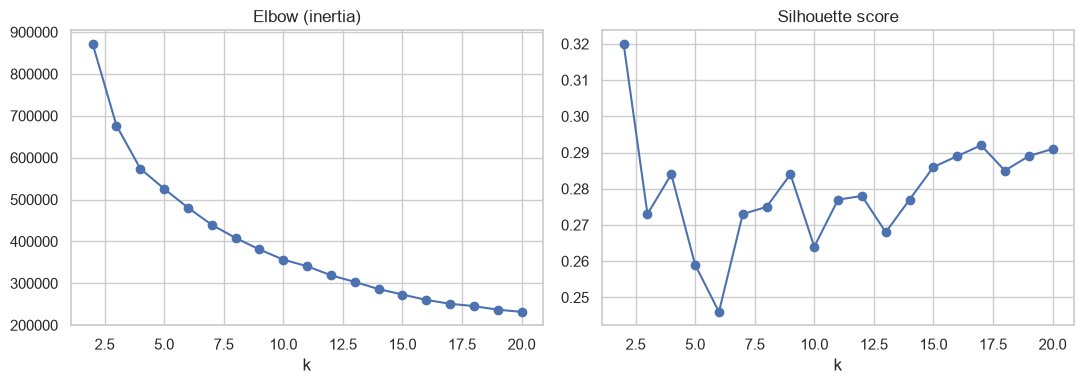

In [44]:
hasil_k = []
for k in range(2, 21):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_base)
    ukuran = np.bincount(km.labels_)
    hasil_k.append({"k": k, "inertia": km.inertia_,
                    "silhouette": silhouette_score(X_base, km.labels_),
                    "davies_bouldin": davies_bouldin_score(X_base, km.labels_),
                    "calinski_harabasz": calinski_harabasz_score(X_base, km.labels_),
                    "ukuran_min": ukuran.min(), "ukuran_maks": ukuran.max(),
                    "ARI_vs_jaringan": adjusted_rand_score(y_ref, km.labels_),     # hanya untuk pelaporan, bukan untuk memilih k
                    "NMI_vs_jaringan": normalized_mutual_info_score(y_ref, km.labels_)})
tabel_k = pd.DataFrame(hasil_k).round(3)
display(tabel_k)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(tabel_k.k, tabel_k.inertia, marker="o"); ax[0].set_title("Elbow (inertia)"); ax[0].set_xlabel("k")
ax[1].plot(tabel_k.k, tabel_k.silhouette, marker="o"); ax[1].set_title("Silhouette score"); ax[1].set_xlabel("k")
plt.tight_layout(); plt.show()

In [45]:
def evaluasi_klaster(X, labels, y):
    ukuran = np.bincount(labels)
    h, c, v = homogeneity_completeness_v_measure(y, labels)
    return {"jumlah_klaster": len(ukuran), "ukuran_min": ukuran.min(), "ukuran_maks": ukuran.max(),
            "silhouette": silhouette_score(X, labels), "davies_bouldin": davies_bouldin_score(X, labels),
            "calinski_harabasz": calinski_harabasz_score(X, labels),
            "ARI_vs_jaringan": adjusted_rand_score(y, labels), "NMI_vs_jaringan": normalized_mutual_info_score(y, labels),
            "homogeneity": h, "completeness": c}

model_baseline = {k: KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_base) for k in [2, 9]}
tabel_baseline = pd.DataFrame({f"K-Means k={k}": evaluasi_klaster(X_base, m.labels_, y_ref)
                               for k, m in model_baseline.items()}).T.round(3)

acak = np.random.default_rng(42).integers(0, 9, len(y_ref))
tabel_baseline.loc["Pembanding acak (k=9)"] = pd.Series(evaluasi_klaster(X_base, acak, y_ref)).round(3)
display(tabel_baseline)

,jumlah_klaster,ukuran_min,ukuran_maks,silhouette,davies_bouldin,calinski_harabasz,ARI_vs_jaringan,NMI_vs_jaringan,homogeneity,completeness
K-Means k=2,2.0,172.0,847.0,0.320,1.120,348.095,0.071,0.280,0.163,0.987
K-Means k=9,9.0,48.0,184.0,0.284,1.368,261.778,0.386,0.513,0.453,0.592
Pembanding acak (k=9),9.0,93.0,133.0,-0.032,22.277,0.740,-0.001,0.032,0.029,0.036


,klaster,n,murni_%,silhouette,tiga_jaringan_teratas,contoh_sel
0,0,105,44,0.33,"CNS 46, FIBROBLAST 37, BONE 7","HS683, NCIH196, MG63"
1,1,184,27,0.15,"LUNG 50, KIDNEY 32, OVARY 16","CAL120, HCC2108, SNU423"
2,2,73,29,0.29,"SOFT_TISSUE 21, LUNG 13, BONE 11","A673, TC71, FUOV1"
3,3,172,100,0.41,HEMATO 172,"KOPN8, RAJI, SKNO1"
4,4,72,56,0.49,"L_INTESTINE 40, STOMACH 18, PANCREAS 5","CCK81, SW1417, HT115"
5,5,180,26,0.22,"LUNG 46, UADT 29, PANCREAS 27","CAOV3, HCC78, SNU869"
6,6,48,94,0.54,"SKIN 45, CNS 3","MELHO, UACC257, MDAMB435S"
7,7,69,74,0.33,"LUNG 51, AUTONOMIC_GANGLIA 11, STOMACH 2","KPNYN, BEN, NCIH2196"
8,8,116,28,0.09,"BREAST 33, LUNG 23, OVARY 16","NCIH2126, BT474, HUH1"


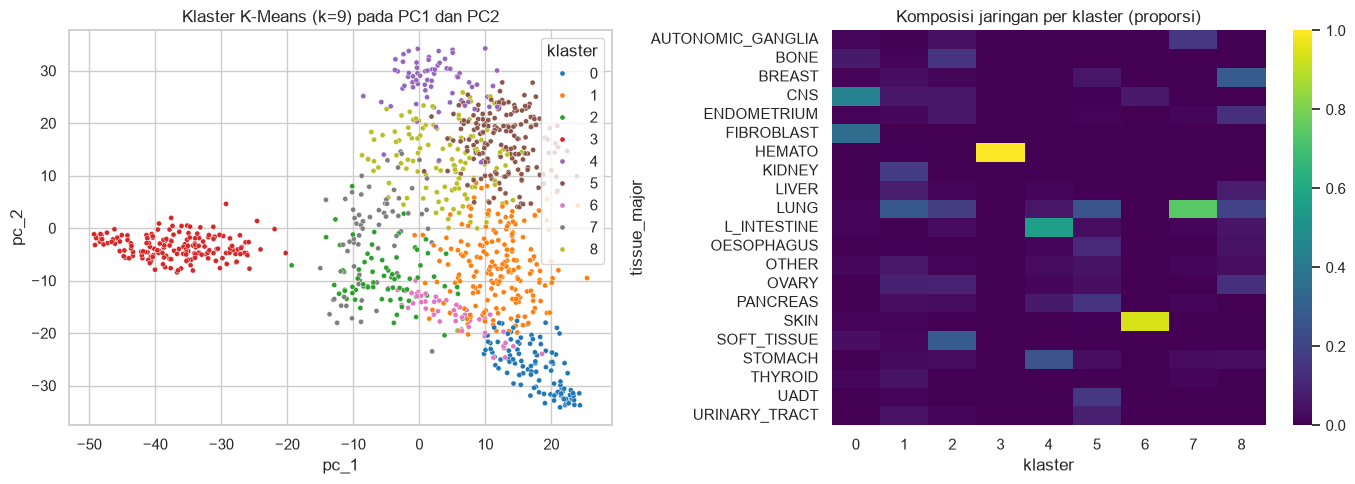

In [46]:
KB = 9
lab = model_baseline[KB].labels_
fs_k = fitur_semua.assign(klaster=lab)
sil_i = silhouette_samples(X_base, lab)
singkat = lambda s: (s.replace("HAEMATOPOIETIC_AND_LYMPHOID_TISSUE", "HEMATO").replace("CENTRAL_NERVOUS_SYSTEM", "CNS")
                      .replace("LARGE_INTESTINE", "L_INTESTINE").replace("UPPER_AERODIGESTIVE_TRACT", "UADT"))
baris = []
for c in range(KB):
    g = fs_k[fs_k.klaster == c]
    vc = g.tissue_major.value_counts()
    baris.append({"klaster": c, "n": len(g), "murni_%": round(vc.iloc[0] / len(g) * 100),
                  "silhouette": round(sil_i[lab == c].mean(), 2),
                  "tiga_jaringan_teratas": ", ".join(f"{singkat(a)} {b}" for a, b in vc.head(3).items()),
                  "contoh_sel": ", ".join(g.sample(min(3, len(g)), random_state=42).index.str.split("_").str[0])})
display(pd.DataFrame(baris))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(x=fs_k.pc_1, y=fs_k.pc_2, hue=fs_k.klaster, palette="tab10", s=14, ax=ax[0])
ax[0].set_title("Klaster K-Means (k=9) pada PC1 dan PC2")
tab = pd.crosstab(fs_k.tissue_major.map(singkat), fs_k.klaster, normalize="columns")
sns.heatmap(tab, cmap="viridis", ax=ax[1]); ax[1].set_title("Komposisi jaringan per klaster (proporsi)")
plt.tight_layout(); plt.show()

In [47]:
gk = fitur_gabungan.join(fs_k[["klaster"]])
display(gk.groupby("klaster").agg(n=("resp_mean_z", "size"), resp_mean_z=("resp_mean_z", "mean"),
                                  resp_frac_sensitif=("resp_frac_sensitif", "mean")).round(2))

k_darah = fs_k.groupby("klaster").hemato.mean().idxmax()
p_semua = kruskal(*[g.resp_mean_z.dropna() for _, g in gk.groupby("klaster")]).pvalue
p_solid = kruskal(*[g.resp_mean_z.dropna() for c, g in gk.groupby("klaster") if c != k_darah]).pvalue
print(f"Klaster sel darah: {k_darah}")
print(f"Kruskal-Wallis resp_mean_z antar klaster: seluruh klaster p = {p_semua:.1e} | tanpa klaster darah p = {p_solid:.1e}")

,n,resp_mean_z,resp_frac_sensitif
klaster,,,
0,39,0.20,0.15
1,113,0.36,0.12
2,46,-0.17,0.27
3,103,-0.87,0.61
4,47,0.25,0.17
5,110,0.30,0.14
6,31,0.17,0.15
7,52,-0.01,0.24
8,77,0.31,0.16


Klaster sel darah: 3
Kruskal-Wallis resp_mean_z antar klaster: seluruh klaster p = 4.4e-48 | tanpa klaster darah p = 7.6e-08


In [48]:
def stabilitas(k, n_run=10):
    labs = [KMeans(n_clusters=k, n_init=1, random_state=s).fit(X_base).labels_ for s in range(n_run)]
    ari = [adjusted_rand_score(a, b) for a, b in combinations(labs, 2)]
    return round(np.mean(ari), 3), round(np.min(ari), 3)

for k in [2, 9]:
    rata, minimum = stabilitas(k)
    print(f"k={k}: ARI antar-inisialisasi rata-rata {rata} | minimum {minimum}")

k=2: ARI antar-inisialisasi rata-rata 0.653 | minimum 0.024
k=9: ARI antar-inisialisasi rata-rata 0.656 | minimum 0.467


# 13. Kandidat Model dan Perbandingan Awal

Ada **empat pendekatan clustering** yang dibandingkan: satu baseline dan tiga kandidat baru. Semuanya memakai ruang fitur PCA yang sama (20 PC). Reduksi dimensinya tetap PCA, tidak diganti.

| No | Pendekatan | Peran | Ide singkat | Catatan |
|---|---|---|---|---|
| 1 | K-Means | Baseline | Membagi data ke *k* kelompok dengan titik pusat (centroid) terdekat | Harus tentukan *k*; cenderung membentuk cluster bulat |
| 2 | Hierarchical (Ward) | Kandidat | Menggabungkan sampel yang mirip sedikit demi sedikit sampai terbentuk pohon (dendrogram), lalu dipotong jadi *k* kelompok | Harus tentukan *k*; hasilnya mudah dilihat lewat dendrogram |
| 3 | DBSCAN | Kandidat | Cluster = area yang padat sampelnya; sampel di area jarang dianggap *noise* (label -1) | **Tidak perlu tentukan *k***, tapi butuh `eps` dan `min_samples` |
| 4 | Gaussian Mixture Model (GMM) | Kandidat | Menganggap data campuran beberapa sebaran normal, tiap sampel punya peluang masuk ke tiap kelompok | Harus tentukan *k*; bisa membentuk cluster lonjong |

Evaluasi mencakup metrik internal (Silhouette, Davies-Bouldin, Calinski-Harabasz), kestabilan (ARI antar-subsampel), dan kesesuaian dengan jaringan asal (ARI dan NMI). **Catatan DBSCAN:** karena tidak punya *k*, jumlah cluster-nya ditentukan data sendiri. Titik *noise* dihitung terpisah dan metrik internalnya hanya memakai titik yang masuk cluster.


In [ ]:
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score,)
from scipy.cluster.hierarchy import linkage, dendrogram

X20 = fitur_semua[[f"pc_{i}" for i in range(1, 21)]].to_numpy()
y_ref = fitur_semua["tissue_major"]
K = 9  # jumlah cluster awal untuk K-Means, Ward, dan GMM (DBSCAN tidak memakai k)

def omega2(nilai, kelompok):
    """Proporsi varians nilai yang dijelaskan kelompok, terkoreksi jumlah kelompok (omega kuadrat)."""
    d = pd.DataFrame({"y": np.asarray(nilai), "g": np.asarray(kelompok)}).dropna()
    n, k = len(d), d.g.nunique()
    rata = d.y.mean()
    ss_t = ((d.y - rata) ** 2).sum()
    ss_b = sum(len(g) * (g.y.mean() - rata) ** 2 for _, g in d.groupby("g"))
    ms_w = (ss_t - ss_b) / (n - k)
    return max(0.0, (ss_b - (k - 1) * ms_w) / (ss_t + ms_w))

def stabilitas_subsampel(buat_model, X, labels_penuh, n_ulang=10, frac=0.8, seed=0):
    """Bandingkan label hasil subsampel dengan label dari seluruh data menggunakan ARI."""
    r = np.random.default_rng(seed)
    ari = []
    for _ in range(n_ulang):
        idx = np.sort(r.choice(len(X), int(frac * len(X)), replace=False))
        ari.append(adjusted_rand_score(labels_penuh[idx], buat_model().fit_predict(X[idx])))
    return round(np.mean(ari), 3), round(np.min(ari), 3)

# --- DBSCAN: menentukan eps dari grafik k-distance ---
MIN_SAMPLES_DB = 10   # ASUMSI: minimal 10 tetangga (cukup kecil agar kelompok kecil tetap bisa jadi cluster)

def eps_knee(P, min_samples=MIN_SAMPLES_DB):
    """eps = titik tekuk (elbow) grafik k-distance, yaitu jarak tiap titik ke tetangga ke-min_samples yang diurutkan."""
    d = np.sort(NearestNeighbors(n_neighbors=min_samples).fit(P).kneighbors(P)[0][:, -1])
    x = np.linspace(0, 1, len(d))
    y = (d - d.min()) / (d.max() - d.min())
    return float(d[np.argmax(x - y)])      # titik terjauh dari garis lurus awal-akhir

eps_db = eps_knee(X20)
print(f"DBSCAN: min_samples = {MIN_SAMPLES_DB} | eps (titik tekuk k-distance) = {eps_db:.2f}")

# Satu baseline dan tiga kandidat baru.
kandidat = {
    "K-Means (baseline)": (lambda: KMeans(n_clusters=K, n_init=10, random_state=42), X20),
    "Agglomerative (Ward)": (lambda: AgglomerativeClustering(n_clusters=K, linkage="ward"), X20),
    "DBSCAN": (lambda: DBSCAN(eps=eps_db, min_samples=MIN_SAMPLES_DB), X20),
    "Gaussian Mixture Model (GMM)": (lambda: GaussianMixture(n_components=K, covariance_type="diag",
                                                               n_init=3, reg_covar=1e-5, random_state=42), X20),
}
labels_kand = {nama: buat().fit_predict(Xm) for nama, (buat, Xm) in kandidat.items()}
print("Empat pendekatan (1 baseline + 3 kandidat baru):", list(labels_kand))


DBSCAN: min_samples = 10 | eps (titik tekuk k-distance) = 19.78
Empat pendekatan (1 baseline + 3 kandidat baru): ['K-Means (baseline)', 'Agglomerative (Ward)', 'DBSCAN', 'Gaussian Mixture Model (GMM)']


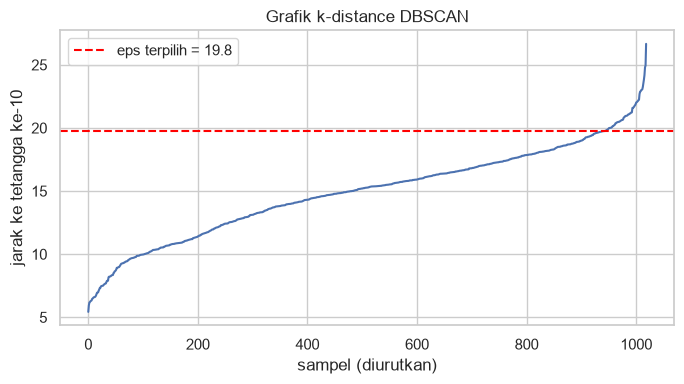

,eps,jumlah_cluster,jumlah_non_noise,noise_%,ukuran_cluster_terbesar,silhouette_tanpa_noise,davies_bouldin
0,15.8,9,843,17.3,462,0.107,1.398
1,17.8,3,974,4.4,772,0.154,1.227
2,19.8,2,1011,0.8,839,0.321,1.119
3,21.8,2,1019,0.0,847,0.320,1.120


ARI antara DBSCAN dan K-Means k=2: 0.968


In [50]:
# Grafik k-distance untuk memilih eps DBSCAN, dan sensitivitas hasil terhadap eps.
d_sorted = np.sort(NearestNeighbors(n_neighbors=MIN_SAMPLES_DB).fit(X20).kneighbors(X20)[0][:, -1])
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(d_sorted)
ax.axhline(eps_db, color="red", ls="--", label=f"eps terpilih = {eps_db:.1f}")
ax.set_xlabel("sampel (diurutkan)"); ax.set_ylabel(f"jarak ke tetangga ke-{MIN_SAMPLES_DB}")
ax.set_title("Grafik k-distance DBSCAN"); ax.legend()
plt.tight_layout(); plt.show()

# Kalau eps diperkecil/diperbesar, hasilnya bagaimana?
baris = []
for faktor in [0.8, 0.9, 1.0, 1.1]:
    lab_d = DBSCAN(eps=eps_db * faktor, min_samples=MIN_SAMPLES_DB).fit_predict(X20)
    ada = lab_d != -1
    n_k = len(np.unique(lab_d[ada])) if ada.any() else 0

    # Hitung metrik hanya jika terdapat minimal 2 cluster
    # dan jumlah sampel lebih banyak daripada jumlah cluster
    cukup_sampel = ada.sum() > n_k

    baris.append({"eps": round(eps_db * faktor, 1), 
                  "jumlah_cluster": n_k,
                  "jumlah_non_noise": int(ada.sum()),
                  "noise_%": round((~ada).mean() * 100, 1),
                  "ukuran_cluster_terbesar": np.bincount(lab_d[ada]).max() if n_k else 0,
                  "silhouette_tanpa_noise": round(silhouette_score(X20[ada], lab_d[ada]), 3) if n_k > 1 and cukup_sampel else np.nan,
                  "davies_bouldin": round(davies_bouldin_score(X20[ada], lab_d[ada]),3) if n_k > 1 and cukup_sampel else np.nan,}
    )
display(pd.DataFrame(baris))

# Apakah DBSCAN menemukan pemisahan yang sama dengan K-Means k=2 (darah vs bukan darah)?
lab_k2 = KMeans(n_clusters=2, n_init=10, random_state=42).fit_predict(X20)
print("ARI antara DBSCAN dan K-Means k=2:", round(adjusted_rand_score(lab_k2, labels_kand["DBSCAN"]), 3))

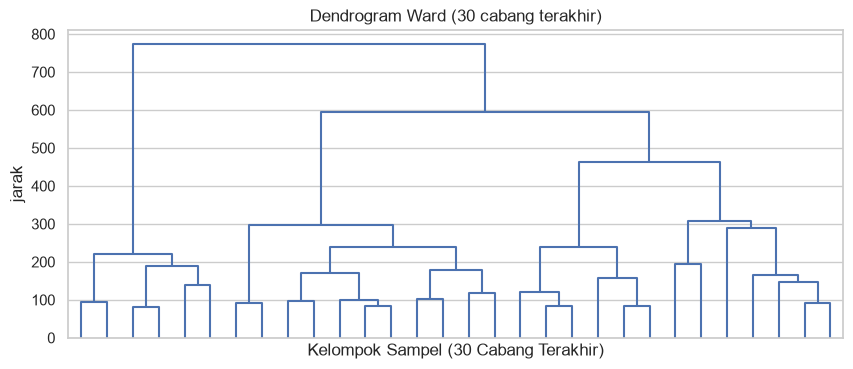

In [51]:
Z = linkage(X20, method="ward")
plt.figure(figsize=(10, 4))
dendrogram(Z, truncate_mode="lastp", p=30, no_labels=True, color_threshold=0)
plt.title("Dendrogram Ward (30 cabang terakhir)");
plt.xlabel("Kelompok Sampel (30 Cabang Terakhir)")
plt.ylabel("jarak");
plt.show()

,k,noise_%,ukuran_min,ukuran_maks,silhouette,davies_bouldin,calinski_harabasz,ARI,NMI,omega2_respons_tumor_padat,stabilitas_ARI_rata2,stabilitas_ARI_min
model,,,,,,,,,,,,
K-Means (baseline),9.0,0.0,48.0,184.0,0.284,1.368,261.778,0.386,0.513,0.072,0.862,0.690
Agglomerative (Ward),9.0,0.0,45.0,193.0,0.270,1.424,246.402,0.394,0.525,0.091,0.787,0.653
DBSCAN,2.0,0.8,172.0,839.0,0.321,1.119,347.742,0.070,0.281,0.000,0.941,0.913
Gaussian Mixture Model (GMM),9.0,0.0,36.0,256.0,0.228,1.367,233.960,0.267,0.513,0.083,0.651,0.530
(acuan) penugasan acak,9.0,0.0,93.0,133.0,-0.032,22.277,0.740,-0.001,0.032,0.000,NaN,NaN
(acuan) jaringan sebenarnya,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.064,NaN,NaN


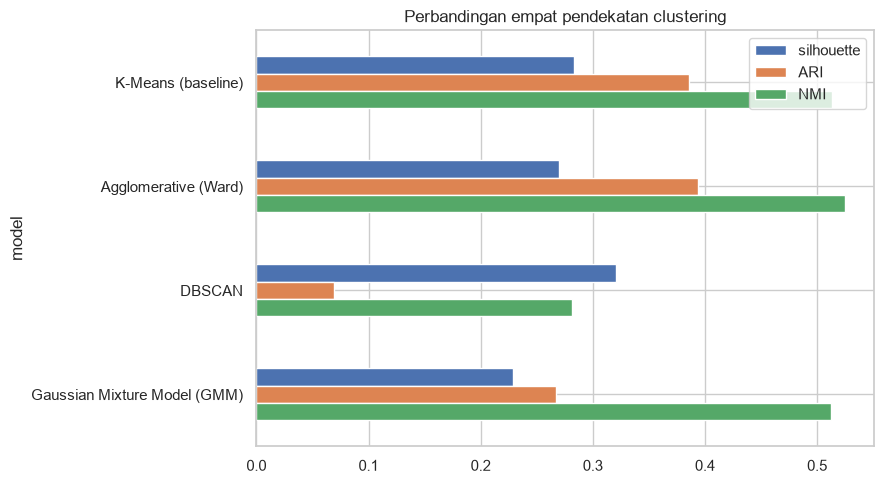

In [52]:
def ringkas(nama, lab, buat=None, Xm=None):
    lab = np.asarray(lab)
    ada = lab != -1                          # label -1 = noise (hanya muncul pada DBSCAN)

    ukuran = np.bincount(lab[ada]) if ada.any() else np.array([])
    n_k = len(np.unique(lab[ada])) if ada.any() else 0

    # Memastikan jumlah sampel cukup untuk menghitung metrik
    cukup_sampel = ada.sum() > n_k
    
    lab_gk = pd.Series(np.where(ada, lab, np.nan), index=fitur_semua.index).reindex(fitur_gabungan.index)
    gk = fitur_gabungan.assign(klaster=lab_gk)
    padat = gk[~gk.hemato & gk.resp_mean_z.notna() & gk.klaster.notna()]
    baris = {"model": nama, "k": n_k, "noise_%": round((~ada).mean() * 100, 1),
             "ukuran_min": ukuran.min(), "ukuran_maks": ukuran.max(),
             # metrik internal hanya memakai titik yang masuk cluster (bukan noise)
             "silhouette": silhouette_score(X20[ada], lab[ada]) if n_k > 1  and cukup_sampel else np.nan,
             "davies_bouldin": davies_bouldin_score(X20[ada], lab[ada]) if n_k > 1  and cukup_sampel else np.nan,
             "calinski_harabasz": calinski_harabasz_score(X20[ada], lab[ada]) if n_k > 1  and cukup_sampel else np.nan,
             # ARI dan NMI: noise dihitung sebagai satu kelompok sendiri
             "ARI": adjusted_rand_score(y_ref, lab), "NMI": normalized_mutual_info_score(y_ref, lab),
             "omega2_respons_tumor_padat": omega2(padat.resp_mean_z, padat.klaster)}
    if buat is not None:
        baris["stabilitas_ARI_rata2"], baris["stabilitas_ARI_min"] = stabilitas_subsampel(buat, Xm, lab)
    return baris

baris_hasil = [ringkas(nama, labels_kand[nama], buat, Xm) for nama, (buat, Xm) in kandidat.items()]
tabel_perbandingan = pd.DataFrame(baris_hasil).set_index("model")
padat_ref = fitur_gabungan[~fitur_gabungan.hemato & fitur_gabungan.resp_mean_z.notna()]
tabel_perbandingan.loc["(acuan) penugasan acak"] = pd.Series(ringkas("acak", np.random.default_rng(42).integers(0, K, len(y_ref))))
tabel_perbandingan.loc["(acuan) jaringan sebenarnya", "omega2_respons_tumor_padat"] = omega2(padat_ref.resp_mean_z, padat_ref.tissue_major)
tabel_perbandingan = tabel_perbandingan.drop(columns="model", errors="ignore")
display(tabel_perbandingan.round(3))
metrik = ["silhouette", "ARI", "NMI"]
ax = tabel_perbandingan.iloc[:len(labels_kand)][metrik].plot(kind="barh", figsize=(9, 5))
ax.invert_yaxis(); ax.set_title("Perbandingan empat pendekatan clustering")
plt.tight_layout(); plt.show()


### Hasil singkat perbandingan awal (K = 9, 20 PC)

- **K-Means vs Ward:** hampir sama bagusnya (Silhouette 0,284 vs 0,270; NMI 0,513 vs 0,525). K-Means lebih stabil (ARI antar-subsampel 0,862 vs 0,787).
- **GMM** paling lemah: Silhouette terendah (0,228) dan paling tidak stabil (0,651).
- **DBSCAN** hanya menemukan **2 cluster** (172 sel darah dan 839 sel lainnya, *noise* 0,8%). Silhouette-nya paling tinggi (0,321) dan stabilitasnya juga tinggi (0,941), tapi itu karena hanya ada 2 kelompok besar yang memang sangat berbeda. Hasilnya hampir sama dengan K-Means k=2 (ARI 0,968), jadi tidak bisa dibandingkan langsung dengan 9 cluster milik yang lain.
- DBSCAN **peka terhadap `eps`**: kalau `eps` dikecilkan 20%, muncul 9 cluster dengan 17,3% *noise*; kalau dibesarkan, tetap 2 cluster.
- DBSCAN juga tidak membedakan respons obat di sel padat (omega² = 0,000, sedangkan K-Means 0,072 dan Ward 0,091), karena semua sel padat masuk ke satu cluster.

**Kesimpulan awal:** K-Means tetap dipakai sebagai baseline. Ward adalah kandidat yang paling mirip. DBSCAN berguna untuk memastikan pemisahan kasar darah vs bukan darah, tetapi tidak untuk memisahkan jaringan padat.


In [53]:
terpilih = "K-Means (baseline)"  # baseline untuk profil cluster awal
lab_t = labels_kand[terpilih]
fs_t = fitur_semua.assign(klaster=lab_t)
singkat = lambda s: (s.replace("HAEMATOPOIETIC_AND_LYMPHOID_TISSUE", "HEMATO").replace("CENTRAL_NERVOUS_SYSTEM", "CNS")
                      .replace("LARGE_INTESTINE", "L_INTESTINE").replace("UPPER_AERODIGESTIVE_TRACT", "UADT"))
sil_t = silhouette_samples(X20, lab_t)
baris = []
for c in sorted(fs_t.klaster.unique()):
    g = fs_t[fs_t.klaster == c]; vc = g.tissue_major.value_counts()
    baris.append({"klaster": c, "n": len(g), "murni_%": round(vc.iloc[0] / len(g) * 100),
                  "silhouette": round(sil_t[lab_t == c].mean(), 2),
                  "tiga_jaringan_teratas": ", ".join(f"{singkat(a)} {b}" for a, b in vc.head(3).items())})
print("Karakteristik klaster:", terpilih); display(pd.DataFrame(baris))


Karakteristik klaster: K-Means (baseline)


,klaster,n,murni_%,silhouette,tiga_jaringan_teratas
0,0,105,44,0.33,"CNS 46, FIBROBLAST 37, BONE 7"
1,1,184,27,0.15,"LUNG 50, KIDNEY 32, OVARY 16"
2,2,73,29,0.29,"SOFT_TISSUE 21, LUNG 13, BONE 11"
3,3,172,100,0.41,HEMATO 172
4,4,72,56,0.49,"L_INTESTINE 40, STOMACH 18, PANCREAS 5"
5,5,180,26,0.22,"LUNG 46, UADT 29, PANCREAS 27"
6,6,48,94,0.54,"SKIN 45, CNS 3"
7,7,69,74,0.33,"LUNG 51, AUTONOMIC_GANGLIA 11, STOMACH 2"
8,8,116,28,0.09,"BREAST 33, LUNG 23, OVARY 16"


# Pertemuan 5: Validasi, Kestabilan, dan Perbandingan Model


In [54]:
# Gunakan hasil preprocessing dan pencocokan pada bagian sebelumnya.
# Tidak memuat ulang dataset atau membuat fungsi pencocokan kedua.
assert "gdsc" in globals() and "expr" in globals() and "peta_plan" in globals()
assert "info_sampel" in globals(), "Jalankan bagian preprocessing terlebih dahulu."

peta_cv = peta_plan.sort_values("COSMIC_ID").reset_index(drop=True).copy()
assert peta_cv["COSMIC_ID"].is_unique and peta_cv["ccle_sample"].is_unique, "Pemetaan harus 1:1."

# expr pada bagian preprocessing berbentuk gen x sampel; ubah menjadi sampel x gen.
X_df = expr.T.loc[peta_cv["ccle_sample"]].copy()
X = X_df.to_numpy(dtype=np.float32)
ids = peta_cv["COSMIC_ID"].to_numpy()

metadata_cv = peta_cv[["COSMIC_ID", "ccle_sample", "tissue_ccle", "metode", "tissue_cocok"]].copy()
metadata_cv = metadata_cv.join(
    info_sampel[["tissue_major", "hemato"]], on="ccle_sample", validate="one_to_one"
)
assert metadata_cv["tissue_ccle"].notna().all(), "Ada label tissue CCLE yang kosong."

# Kelompok kecil digabung hanya untuk stratifikasi; label asli tetap disimpan.
jumlah_tissue = metadata_cv["tissue_ccle"].value_counts()
jaringan = metadata_cv["tissue_ccle"].where(
    metadata_cv["tissue_ccle"].map(jumlah_tissue) >= 10, "LAINNYA"
).to_numpy()

# Respons tetap dibedakan berdasarkan DRUG_ID, bukan DRUG_NAME.
kolom_resp = ["COSMIC_ID", "DRUG_ID", "DRUG_NAME", "LN_IC50", "AUC", "Z_SCORE", "TARGET", "TARGET_PATHWAY"]
respons_cv = gdsc.loc[gdsc["COSMIC_ID"].isin(ids), kolom_resp].copy()
respons_cv["DRUG_NAME"] = respons_cv["DRUG_NAME"].astype(str).str.strip()
respons_cv = (respons_cv.groupby(["COSMIC_ID", "DRUG_ID"], as_index=False)
              .agg(DRUG_NAME=("DRUG_NAME", "first"), LN_IC50=("LN_IC50", "mean"),
                   AUC=("AUC", "mean"), Z_SCORE=("Z_SCORE", "mean"),
                   TARGET=("TARGET", "first"), TARGET_PATHWAY=("TARGET_PATHWAY", "first"),
                   n_pengukuran=("LN_IC50", "size")))

print("Matriks ekspresi:", X.shape, "| cell line:", len(ids))
print("Respons obat:", respons_cv.shape, "| DRUG_ID:", respons_cv.DRUG_ID.nunique())
print("Jaringan untuk stratifikasi:")
print(pd.Series(jaringan).value_counts().to_string())


Matriks ekspresi: (621, 57820) | cell line: 621
Respons obat: (157558, 9) | DRUG_ID: 295
Jaringan untuk stratifikasi:
LUNG                                  131
HAEMATOPOIETIC_AND_LYMPHOID_TISSUE    103
BREAST                                 45
LARGE_INTESTINE                        40
CENTRAL_NERVOUS_SYSTEM                 33
SKIN                                   32
PANCREAS                               28
OVARY                                  28
LAINNYA                                27
OESOPHAGUS                             24
STOMACH                                22
URINARY_TRACT                          16
KIDNEY                                 15
UPPER_AERODIGESTIVE_TRACT              15
SOFT_TISSUE                            14
BONE                                   13
LIVER                                  13
AUTONOMIC_GANGLIA                      12
ENDOMETRIUM                            10


In [55]:
# Validasi konsistensi data sebelum pembagian development/test.
assert X.ndim == 2 and X.shape[0] == len(ids) == len(metadata_cv)
assert np.isfinite(X).all(), "Matriks ekspresi mengandung NaN/inf."
assert (X >= 0).all(), "TPM tidak boleh negatif."
assert metadata_cv["COSMIC_ID"].is_unique
assert not respons_cv.duplicated(["COSMIC_ID", "DRUG_ID"]).any()
assert set(respons_cv.COSMIC_ID).issubset(set(ids))
assert len(jaringan) == len(X)
print("Validasi data Pertemuan 5 lulus.")
print("Jumlah sampel:", len(X), "| jumlah gen:", X.shape[1], "| kategori stratifikasi:", pd.Series(jaringan).nunique())


Validasi data Pertemuan 5 lulus.
Jumlah sampel: 621 | jumlah gen: 57820 | kategori stratifikasi: 19


### Catatan pipeline data

Data ekspresi, metadata jaringan, dan respons obat pada pertemuan ini menggunakan hasil preprocessing sebelumnya. Pencocokan identitas tidak diulang agar seluruh bagian notebook memakai pemetaan *cell line* yang sama. Respons obat dipertahankan berdasarkan `DRUG_ID` sehingga dua ID obat dengan nama yang sama tidak digabung secara otomatis.


### Variabel analisis

- `X`: matriks TPM mentah untuk sampel yang berhasil dipasangkan, dengan baris = *cell line* dan kolom = gen.
- `ids`: `COSMIC_ID` dengan urutan yang sama seperti baris `X`.
- `jaringan`: label `tissue_ccle` yang kategori kecilnya digabung menjadi `LAINNYA` khusus untuk stratifikasi.
- `respons_cv`: data respons obat yang tetap dibedakan berdasarkan `DRUG_ID`.


# Tugas 1. Audit strategi validasi

In [56]:
# Pembagian data
from matplotlib.patches import FancyBboxPatch, Patch
from scipy.stats import kruskal, false_discovery_control
from sklearn.model_selection import train_test_split, StratifiedKFold

semua = np.arange(len(X))
dev, test = train_test_split(semua, test_size=UKURAN_TEST, stratify=jaringan, random_state=SEED)

skf = StratifiedKFold(N_FOLD, shuffle=True, random_state=SEED)
lipatan = list(skf.split(dev, jaringan[dev]))

print(f"Development set: {len(dev)} sel | Test set (dikunci): {len(test)} sel")
print("Tidak ada sel yang sama di dev dan test:", np.intersect1d(dev, test).size == 0)

# komposisi jaringan tiap bagian (persen), untuk memastikan pembagian merata
komposisi = pd.DataFrame({"semua": pd.Series(jaringan).value_counts(normalize=True)})
komposisi["dev"] = pd.Series(jaringan[dev]).value_counts(normalize=True)
komposisi["test"] = pd.Series(jaringan[test]).value_counts(normalize=True)
for i, (a, b) in enumerate(lipatan, 1):
    komposisi[f"fold{i}_val"] = pd.Series(jaringan[dev[b]]).value_counts(normalize=True)
display((komposisi.fillna(0) * 100).round(1))
print("Ukuran tiap fold (latih / validasi):", [(len(a), len(b)) for a, b in lipatan])

Development set: 496 sel | Test set (dikunci): 125 sel
Tidak ada sel yang sama di dev dan test: True


,semua,dev,test,fold1_val,fold2_val,fold3_val,fold4_val,fold5_val
LUNG,21.1,21.2,20.8,21.0,21.2,21.2,21.2,21.2
HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,16.6,16.5,16.8,17.0,17.2,16.2,16.2,16.2
BREAST,7.2,7.3,7.2,8.0,7.1,7.1,7.1,7.1
LARGE_INTESTINE,6.4,6.5,6.4,6.0,6.1,7.1,7.1,6.1
CENTRAL_NERVOUS_SYSTEM,5.3,5.2,5.6,5.0,6.1,5.1,5.1,5.1
SKIN,5.2,5.2,4.8,5.0,6.1,5.1,5.1,5.1
PANCREAS,4.5,4.4,4.8,4.0,4.0,5.1,5.1,4.0
OVARY,4.5,4.4,4.8,4.0,4.0,5.1,5.1,4.0
LAINNYA,4.3,4.4,4.0,4.0,5.1,5.1,4.0,4.0
OESOPHAGUS,3.9,3.8,4.0,4.0,4.0,4.0,3.0,4.0


Ukuran tiap fold (latih / validasi): [(396, 100), (397, 99), (397, 99), (397, 99), (397, 99)]


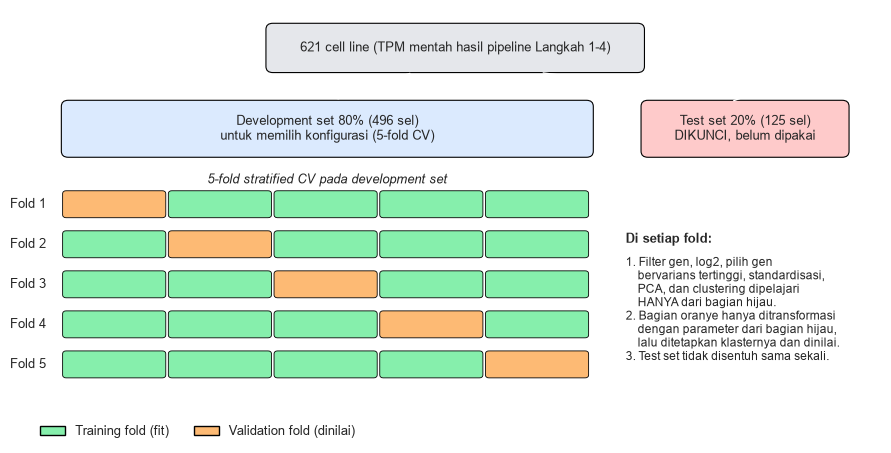

In [57]:
# Diagram pembagian data
fig, ax = plt.subplots(figsize=(11, 5.6))
ax.set_xlim(0, 100); ax.set_ylim(0, 56); ax.axis("off")

def kotak(x, y, w, h, teks, warna, ukuran=9):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.2,rounding_size=0.8", fc=warna, ec="black", lw=0.8))
    ax.text(x + w / 2, y + h / 2, teks, ha="center", va="center", fontsize=ukuran)

kotak(28, 48, 44, 6, f"{len(X)} cell line (TPM mentah hasil pipeline Langkah 1-4)", "#e5e7eb")
kotak(4, 37, 62, 7, f"Development set 80% ({len(dev)} sel)\nuntuk memilih konfigurasi (5-fold CV)", "#dbeafe")
kotak(72, 37, 24, 7, f"Test set 20% ({len(test)} sel)\nDIKUNCI, belum dipakai", "#fecaca")
ax.annotate("", xy=(35, 44.4), xytext=(45, 47.8), arrowprops=dict(arrowstyle="->"))
ax.annotate("", xy=(84, 44.4), xytext=(60, 47.8), arrowprops=dict(arrowstyle="->"))

for f in range(N_FOLD):
    y = 29 - f * 5.2
    ax.text(2, y + 1.7, f"Fold {f + 1}", ha="right", va="center", fontsize=9)
    for j in range(N_FOLD):
        warna = "#fdba74" if j == f else "#86efac"
        ax.add_patch(FancyBboxPatch((4 + j * 12.4, y), 12.0, 3.4, boxstyle="round,pad=0.05,rounding_size=0.4", fc=warna, ec="black", lw=0.6))
ax.text(35, 33.4, "5-fold stratified CV pada development set", ha="center", fontsize=9, style="italic")

ax.text(70, 27, "Di setiap fold:", fontsize=9.5, weight="bold", va="top")
ax.text(70, 24, "1. Filter gen, log2, pilih gen\n    bervarians tertinggi, standardisasi,\n    PCA, dan clustering dipelajari\n    HANYA dari bagian hijau.\n"
        "2. Bagian oranye hanya ditransformasi\n    dengan parameter dari bagian hijau,\n    lalu ditetapkan klasternya dan dinilai.\n"
        "3. Test set tidak disentuh sama sekali.", fontsize=8.6, va="top")
ax.legend(handles=[Patch(fc="#86efac", ec="black", label="Training fold (fit)"),
                   Patch(fc="#fdba74", ec="black", label="Validation fold (dinilai)")],
          loc="lower left", bbox_to_anchor=(0.0, -0.02), frameon=False, ncol=2, fontsize=9)
plt.show()

In [ ]:
# ===== Komponen eksperimen: preprocessing hanya di-fit pada data latih =====
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from scipy.spatial.distance import cdist
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, normalized_mutual_info_score)
from sklearn.model_selection import StratifiedKFold

class Transformasi:
    """Filter gen aktif -> log2(TPM+1) -> pilih gen varians tertinggi -> standardisasi.
    Semua parameter dipelajari hanya dari data yang diberikan ke fit()."""
    def __init__(self, n_gen=N_GEN, ambang=AMBANG_TPM, prop=PROPORSI_SAMPEL):
        self.n_gen, self.ambang, self.prop = n_gen, ambang, prop

    def fit(self, X_fit):
        X_fit = np.asarray(X_fit, dtype=np.float64)
        if X_fit.ndim != 2 or not np.isfinite(X_fit).all():
            raise ValueError("X_fit harus berupa matriks 2D tanpa NaN/inf.")
        aktif = np.flatnonzero((X_fit > self.ambang).mean(axis=0) >= self.prop)
        if len(aktif) == 0:
            raise ValueError("Tidak ada gen yang lolos filter gen aktif pada data latih.")
        L = np.log2(X_fit[:, aktif] + 1.0)
        varians = L.var(axis=0)
        urut = np.argsort(varians)[::-1][:min(self.n_gen, len(aktif))]
        idx = aktif[urut]
        Lt = L[:, urut]
        sd = Lt.std(axis=0, ddof=0)
        valid = sd > 1e-12
        self.idx_ = idx[valid]
        self.mean_ = Lt.mean(axis=0)[valid]
        self.scale_ = sd[valid]
        if len(self.idx_) == 0:
            raise ValueError("Tidak ada gen dengan varians positif setelah seleksi.")
        self.n_features_in_ = X_fit.shape[1]
        return self

    def transform(self, X_new):
        X_new = np.asarray(X_new, dtype=np.float64)
        if X_new.ndim != 2 or X_new.shape[1] != self.n_features_in_:
            raise ValueError("Jumlah kolom X_new tidak sesuai dengan data saat fit().")
        if not np.isfinite(X_new).all() or (X_new < 0).any():
            raise ValueError("X_new harus berisi TPM valid dan tidak negatif.")
        return (np.log2(X_new[:, self.idx_] + 1.0) - self.mean_) / self.scale_


def bagi_klaster(metode, P, k, seed=SEED):
    if metode == "kmeans":
        return KMeans(n_clusters=k, n_init=10, random_state=seed).fit_predict(P)
    if metode == "ward":
        return AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(P)
    if metode == "gmm":
        return GaussianMixture(n_components=k, covariance_type="diag", n_init=3,
                               reg_covar=1e-5, random_state=seed).fit_predict(P)
    if metode == "dbscan":
        return ModelDBSCAN().fit(P).labels_
    raise ValueError(f"Metode tidak dikenal: {metode}")


def tetapkan(P_latih, label_latih, P_baru):
    """Tetapkan sampel baru ke centroid terdekat dari klaster data latih."""
    kelas = np.unique(label_latih)
    centroid = np.vstack([P_latih[label_latih == c].mean(axis=0) for c in kelas])
    jarak = ((P_baru[:, None, :] - centroid[None, :, :]) ** 2).sum(axis=2)
    return kelas[jarak.argmin(axis=1)]


# ===== DBSCAN: tidak memakai k; eps dihitung ulang dari data latih tiap fold (titik tekuk k-distance) =====
MIN_SAMPLES_DB = 10   # ASUMSI: minimal 10 tetangga

def eps_knee(P, min_samples=MIN_SAMPLES_DB):
    d = np.sort(NearestNeighbors(n_neighbors=min_samples).fit(P).kneighbors(P)[0][:, -1])
    x = np.linspace(0, 1, len(d))
    y = (d - d.min()) / (d.max() - d.min())
    return float(d[np.argmax(x - y)])


class ModelDBSCAN:
    """DBSCAN dengan aturan penetapan sampel baru: ikut cluster core point terdekat bila jaraknya <= eps, selain itu noise (-1)."""
    def __init__(self, min_samples=MIN_SAMPLES_DB, faktor_eps=1.0):
        self.min_samples, self.faktor_eps = min_samples, faktor_eps

    def fit(self, P):
        self.eps_ = eps_knee(P, self.min_samples) * self.faktor_eps
        m = DBSCAN(eps=self.eps_, min_samples=self.min_samples).fit(P)
        self.labels_ = m.labels_
        self.inti_ = P[m.core_sample_indices_]
        self.label_inti_ = m.labels_[m.core_sample_indices_]
        return self

    def predict(self, P_baru):
        if len(self.inti_) == 0:
            return np.full(len(P_baru), -1)
        jarak = cdist(P_baru, self.inti_)
        j = jarak.argmin(axis=1)
        lab = self.label_inti_[j].copy()
        lab[jarak[np.arange(len(P_baru)), j] > self.eps_] = -1
        return lab


_cache = {}
def siapkan(n_gen=N_GEN, seed_lipatan=SEED):
    """Fit transformasi/PCA pada development set dan ulangi dari awal di tiap fold."""
    key = (n_gen, seed_lipatan)
    if key in _cache:
        return _cache[key]
    transform_dev = Transformasi(n_gen).fit(X[dev])
    Zd = transform_dev.transform(X[dev])
    pca_dev = PCA(n_components=50, random_state=SEED).fit(Zd)
    Pd = pca_dev.transform(Zd)
    hasil = {"ref": (Zd, Pd), "lipat": [], "transform_dev": transform_dev, "pca_dev": pca_dev}
    splitter = StratifiedKFold(N_FOLD, shuffle=True, random_state=seed_lipatan)
    for a, b in splitter.split(dev, jaringan[dev]):
        tr = Transformasi(n_gen).fit(X[dev[a]])
        Zt, Zv = tr.transform(X[dev[a]]), tr.transform(X[dev[b]])
        pca = PCA(n_components=50, random_state=SEED).fit(Zt)
        hasil["lipat"].append({"a": a, "b": b, "Zt": Zt, "Zv": Zv,
                               "Pt": pca.transform(Zt), "Pv": pca.transform(Zv)})
    _cache[key] = hasil
    return hasil


def ruang(T, npc):
    return T if npc is None else T[:, :npc]


def buat_label(metode, T, k, npc):
    return bagi_klaster(metode, ruang(T, npc), k)


def jalankan_cv(metode="kmeans", k=4, npc=10, n_gen=N_GEN, seed_lipatan=SEED, db_faktor_eps=1.0, db_min_samples=None):
    """5-fold CV di development set. Test set tidak digunakan pada tahap ini.
    metode: kmeans, ward, gmm, atau dbscan (DBSCAN tidak memakai k)."""
    assert np.intersect1d(dev, test).size == 0, "Test set bocor ke development set."
    ms = MIN_SAMPLES_DB if db_min_samples is None else db_min_samples
    h = siapkan(n_gen, seed_lipatan)
    Zd, Pd = h["ref"]
    if metode == "dbscan":
        ref = ModelDBSCAN(ms, db_faktor_eps).fit(ruang(Zd if npc is None else Pd, npc)).labels_
    else:
        ref = buat_label(metode, Zd if npc is None else Pd, k, npc)
    baris = []
    for f, L in enumerate(h["lipat"], 1):
        Tt, Tv = (L["Zt"], L["Zv"]) if npc is None else (L["Pt"], L["Pv"])
        St, Sv = ruang(Tt, npc), ruang(Tv, npc)
        if metode == "dbscan":
            model = ModelDBSCAN(ms, db_faktor_eps).fit(St)      # eps dihitung dari data latih fold ini
            lv = model.predict(Sv)                              # sel validasi: core point terdekat atau noise
        else:
            lt = buat_label(metode, Tt, k, npc)
            lv = tetapkan(St, lt, Sv)
        ada = lv != -1                                          # -1 = noise (hanya DBSCAN)
        n_k = len(np.unique(lv[ada]))
        r = {"fold": f, "n_klaster": n_k, "pct_noise": (~ada).mean() * 100,
             # ARI ini mengukur konsistensi terhadap partisi acuan development, bukan akurasi prediksi.
             "ari_ref": adjusted_rand_score(ref[L["b"]], lv),
             "ari_jaringan": adjusted_rand_score(jaringan[dev[L["b"]]], lv),
             "nmi_jaringan": normalized_mutual_info_score(jaringan[dev[L["b"]]], lv),
             "sil": np.nan, "db": np.nan, "ch": np.nan}
        if n_k > 1 and ada.sum() > n_k:                         # metrik internal hanya pada titik non-noise
            r.update(sil=silhouette_score(Sv[ada], lv[ada]), db=davies_bouldin_score(Sv[ada], lv[ada]),
                     ch=calinski_harabasz_score(Sv[ada], lv[ada]))
        baris.append(r)
    return pd.DataFrame(baris)


def mean_sd(df, kolom, desimal=3):
    return f"{df[kolom].mean():.{desimal}f} ± {df[kolom].std():.{desimal}f}"

print("Komponen eksperimen siap. Preprocessing akan di-fit ulang pada setiap fold.")


Komponen eksperimen siap. Preprocessing akan di-fit ulang pada setiap fold.



# Tugas 2. Uji kestabilan model

In [59]:
# Pilih jumlah cluster K untuk baseline K-Means melalui grid 5-fold CV.
baris = []
for k in range(2, 13):
    r = jalankan_cv("kmeans", k, N_PC)
    baris.append({"k": k, "sil": r.sil.mean(), "sil_sd": r.sil.std(),
                  "ari": r.ari_ref.mean(), "ari_sd": r.ari_ref.std(),
                  "ari_jaringan": r.ari_jaringan.mean()})
grid = pd.DataFrame(baris).set_index("k")
display(grid.round(3))


,sil,sil_sd,ari,ari_sd,ari_jaringan
k,,,,,
2,0.337,0.024,1.000,0.000,0.074
3,0.269,0.019,0.978,0.020,0.153
4,0.282,0.023,0.981,0.032,0.186
5,0.254,0.015,0.910,0.075,0.236
6,0.261,0.023,0.815,0.108,0.262
7,0.255,0.024,0.769,0.141,0.303
8,0.261,0.038,0.844,0.142,0.272
9,0.260,0.021,0.801,0.146,0.257
10,0.245,0.017,0.787,0.104,0.252


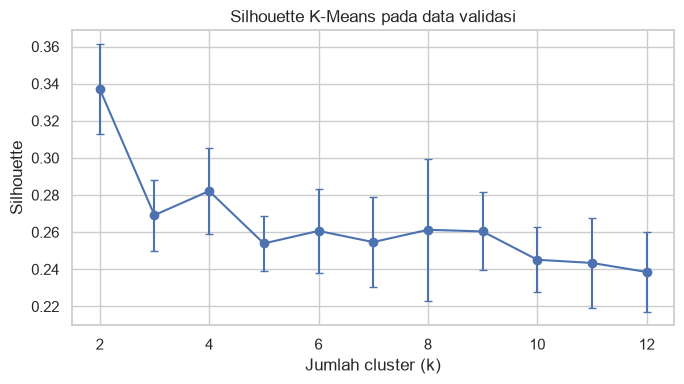

In [60]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(grid.index, grid.sil, yerr=grid.sil_sd, marker="o", capsize=3)
ax.set_title("Silhouette K-Means pada data validasi")
ax.set_xlabel("Jumlah cluster (k)"); ax.set_ylabel("Silhouette")
plt.tight_layout(); plt.show()


In [61]:
# Jumlah PC baseline mengikuti hasil Initial Feature Engineering (N_PC = 20).
N_PC_BASELINE = N_PC
kb = grid.sort_index()      # grid (sel 101) sudah khusus K-Means pada N_PC_BASELINE
kandidat_k = kb[(kb.index >= 3) & (kb.ari >= 0.90)]
if not kandidat_k.empty:
    K_BASELINE = int(kandidat_k.sil.idxmax())
    alasan_k = "silhouette tertinggi di antara k >= 3 dengan ARI kestabilan >= 0,90"
else:
    kandidat_k = kb[kb.index >= 3]
    if kandidat_k.empty:
        raise ValueError("Tidak tersedia kandidat k >= 3 pada hasil validasi.")
    # Jika tidak ada yang melewati ambang, prioritaskan kestabilan lalu silhouette.
    K_BASELINE = int(kandidat_k.sort_values(["ari", "sil"], ascending=False).index[0])
    alasan_k = "ARI kestabilan tertinggi (tidak ada kandidat yang mencapai 0,90)"
print("Jumlah PC baseline:", N_PC_BASELINE)
print("K yang dipilih:", K_BASELINE, "| dasar pemilihan:", alasan_k)
display(kb.round(3))


Jumlah PC baseline: 20
K yang dipilih: 4 | dasar pemilihan: silhouette tertinggi di antara k >= 3 dengan ARI kestabilan >= 0,90


,sil,sil_sd,ari,ari_sd,ari_jaringan
k,,,,,
2,0.337,0.024,1.000,0.000,0.074
3,0.269,0.019,0.978,0.020,0.153
4,0.282,0.023,0.981,0.032,0.186
5,0.254,0.015,0.910,0.075,0.236
6,0.261,0.023,0.815,0.108,0.262
7,0.255,0.024,0.769,0.141,0.303
8,0.261,0.038,0.844,0.142,0.272
9,0.260,0.021,0.801,0.146,0.257
10,0.245,0.017,0.787,0.104,0.252


In [62]:
# Tabel hasil validasi per fold untuk baseline
base = jalankan_cv("kmeans", K_BASELINE, N_PC_BASELINE)

tabel = pd.DataFrame({"Fold": [f"Fold {i}" for i in base.fold],
                      "Silhouette (data validasi)": base.sil.round(3).to_numpy(),
                      "ARI vs partisi acuan": base.ari_ref.round(3).to_numpy(),
                      "Davies-Bouldin": base.db.round(3).to_numpy(),
                      "ARI vs jaringan": base.ari_jaringan.round(3).to_numpy()})
ringkasan = pd.DataFrame({"Fold": ["Rata-rata", "Standar deviasi"],
                          "Silhouette (data validasi)": [base.sil.mean(), base.sil.std()],
                          "ARI vs partisi acuan": [base.ari_ref.mean(), base.ari_ref.std()],
                          "Davies-Bouldin": [base.db.mean(), base.db.std()],
                          "ARI vs jaringan": [base.ari_jaringan.mean(), base.ari_jaringan.std()]}).round(3)
display(pd.concat([tabel, ringkasan], ignore_index=True))

,Fold,Silhouette (data validasi),ARI vs partisi acuan,Davies-Bouldin,ARI vs jaringan
0,Fold 1,0.265,1.000,1.372,0.199
1,Fold 2,0.307,1.000,1.228,0.203
2,Fold 3,0.308,1.000,1.204,0.173
3,Fold 4,0.270,0.926,1.328,0.175
4,Fold 5,0.261,0.977,1.336,0.181
5,Rata-rata,0.282,0.981,1.294,0.186
6,Standar deviasi,0.023,0.032,0.073,0.014


In [63]:
# Apakah hasil tetap stabil bila pembagian data diubah? Ulangi 5-fold CV dengan 5 pengacakan berbeda
rep = []
for s in [1, 2, 3, 4, 5]:
    r = jalankan_cv("kmeans", K_BASELINE, N_PC_BASELINE, seed_lipatan=s)
    rep.append({"Pengacakan (seed)": s, "Silhouette rata-rata": r.sil.mean(), "ARI rata-rata": r.ari_ref.mean(), "ARI terendah": r.ari_ref.min()})
rep = pd.DataFrame(rep)
display(rep.round(3))
print("Antar pengacakan: Silhouette", f"{rep['Silhouette rata-rata'].mean():.3f} ± {rep['Silhouette rata-rata'].std():.3f}",
      "| ARI", f"{rep['ARI rata-rata'].mean():.3f} ± {rep['ARI rata-rata'].std():.3f}")

,Pengacakan (seed),Silhouette rata-rata,ARI rata-rata,ARI terendah
0,1,0.282,0.994,0.968
1,2,0.280,0.996,0.978
2,3,0.282,0.987,0.958
3,4,0.281,0.983,0.950
4,5,0.279,0.984,0.967


Antar pengacakan: Silhouette 0.281 ± 0.001 | ARI 0.989 ± 0.006


# Tugas 3. Perbandingan empat pendekatan clustering

Empat pendekatan dibandingkan lagi dengan validasi silang: **K-Means (baseline)**, **Hierarchical Ward**, **DBSCAN**, dan **Gaussian Mixture Model (GMM)**. Semuanya memakai fold yang sama dan PCA yang sama.

Perbedaan yang perlu diingat: K-Means, Ward, dan GMM memakai jumlah cluster *k* yang sama (`K_BASELINE`), sedangkan **DBSCAN tidak punya *k***. Jumlah cluster DBSCAN ditentukan data, dan `eps`-nya dihitung ulang dari data latih tiap fold. Karena jumlah cluster bisa berbeda, nilai Silhouette antar-pendekatan tidak bisa dibandingkan begitu saja. Karena itu tabel juga menampilkan jumlah cluster dan persen *noise*.


In [64]:
# Perbandingan empat pendekatan pada fold dan jumlah PC yang sama (K-Means, Ward, GMM memakai K_BASELINE; DBSCAN tanpa k).
konfigurasi = [
    ("K-Means (baseline)", "kmeans", N_PC_BASELINE),
    ("Agglomerative Ward", "ward", N_PC_BASELINE),
    ("DBSCAN", "dbscan", N_PC_BASELINE),
    ("Gaussian Mixture Model (GMM)", "gmm", N_PC_BASELINE),
]
hasil = []
for nama, metode, npc in konfigurasi:
    r = jalankan_cv(metode, K_BASELINE, npc)
    hasil.append({"Model": nama,
                  "Rata-rata Jumlah cluster": f"{r.n_klaster.mean():.1f}",
                  "Rata- rata Noise (%)": f"{r.pct_noise.mean():.1f}",
                  "Silhouette": mean_sd(r, "sil"),
                  "Davies-Bouldin": mean_sd(r, "db"),
                  "Konsistensi ARI": mean_sd(r, "ari_ref"),
                  "ARI vs jaringan": mean_sd(r, "ari_jaringan"),
                  "NMI vs jaringan": mean_sd(r, "nmi_jaringan")})
perbandingan = pd.DataFrame(hasil).set_index("Model")
display(perbandingan)


,Rata-rata Jumlah cluster,Rata- rata Noise (%),Silhouette,Davies-Bouldin,Konsistensi ARI,ARI vs jaringan,NMI vs jaringan
Model,,,,,,,
K-Means (baseline),4.0,0.0,0.282 ± 0.023,1.294 ± 0.073,0.981 ± 0.032,0.186 ± 0.014,0.450 ± 0.022
Agglomerative Ward,4.0,0.0,0.278 ± 0.024,1.310 ± 0.118,0.676 ± 0.068,0.177 ± 0.018,0.442 ± 0.014
DBSCAN,2.0,0.0,0.337 ± 0.024,1.054 ± 0.070,0.952 ± 0.033,0.074 ± 0.004,0.292 ± 0.006
Gaussian Mixture Model (GMM),4.0,0.0,0.270 ± 0.041,1.322 ± 0.120,0.756 ± 0.149,0.166 ± 0.052,0.438 ± 0.040


In [65]:
# Kestabilan pada beberapa nilai k untuk metode yang memakai k (3 pengacakan fold x 5 fold).
baris = []
for k in sorted(set([K_BASELINE, 6, 8])):
    for nama, metode in [("K-Means", "kmeans"), ("Agglomerative Ward", "ward"), ("Gaussian Mixture Model", "gmm")]:
        r = pd.concat([jalankan_cv(metode, k, N_PC_BASELINE, seed_lipatan=s) for s in [1, 2, 3]],
                      ignore_index=True)
        baris.append({"k": k, "Metode": nama, "Silhouette": mean_sd(r, "sil"),
                      "Konsistensi ARI": mean_sd(r, "ari_ref"),
                      "ARI terendah": round(r.ari_ref.min(), 3),
                      "ARI vs jaringan": mean_sd(r, "ari_jaringan")})
display(pd.DataFrame(baris))

# DBSCAN tidak punya k, jadi yang diuji adalah kepekaannya terhadap eps dan min_samples.
baris = []
for ms, faktor in [(10, 0.8), (10, 0.9), (10, 1.0), (10, 1.1), (5, 1.0), (20, 1.0)]:
    r = pd.concat([jalankan_cv("dbscan", K_BASELINE, N_PC_BASELINE, seed_lipatan=s, db_faktor_eps=faktor, db_min_samples=ms)
                   for s in [1, 2, 3]], ignore_index=True)
    baris.append({"min_samples": ms, "faktor_eps": faktor, "Jumlah cluster": f"{r.n_klaster.mean():.1f}",
                  "Noise (%)": f"{r.pct_noise.mean():.1f}", "Silhouette": mean_sd(r, "sil"),
                  "Konsistensi ARI": mean_sd(r, "ari_ref"), "ARI vs jaringan": mean_sd(r, "ari_jaringan")})
print("DBSCAN: kepekaan terhadap eps (faktor x eps titik tekuk) dan min_samples")
display(pd.DataFrame(baris))


,k,Metode,Silhouette,Konsistensi ARI,ARI terendah,ARI vs jaringan
0,4,K-Means,0.281 ± 0.023,0.992 ± 0.014,0.958,0.187 ± 0.015
1,4,Agglomerative Ward,0.275 ± 0.024,0.717 ± 0.086,0.594,0.188 ± 0.021
2,4,Gaussian Mixture Model,0.264 ± 0.022,0.761 ± 0.117,0.529,0.186 ± 0.024
3,6,K-Means,0.253 ± 0.032,0.768 ± 0.094,0.576,0.273 ± 0.034
4,6,Agglomerative Ward,0.258 ± 0.022,0.659 ± 0.063,0.563,0.263 ± 0.031
5,6,Gaussian Mixture Model,0.239 ± 0.032,0.646 ± 0.099,0.505,0.229 ± 0.053
6,8,K-Means,0.258 ± 0.039,0.795 ± 0.103,0.657,0.276 ± 0.059
7,8,Agglomerative Ward,0.258 ± 0.021,0.737 ± 0.066,0.636,0.297 ± 0.058
8,8,Gaussian Mixture Model,0.240 ± 0.034,0.431 ± 0.060,0.359,0.255 ± 0.073


DBSCAN: kepekaan terhadap eps (faktor x eps titik tekuk) dan min_samples


,min_samples,faktor_eps,Jumlah cluster,Noise (%),Silhouette,Konsistensi ARI,ARI vs jaringan
0,10,0.8,8.8,15.4,0.210 ± 0.063,0.498 ± 0.172,0.117 ± 0.046
1,10,0.9,2.9,1.6,0.266 ± 0.087,0.624 ± 0.116,0.087 ± 0.019
2,10,1.0,2.1,0.1,0.334 ± 0.036,0.946 ± 0.057,0.077 ± 0.010
3,10,1.1,2.0,0.0,0.340 ± 0.020,1.000 ± 0.000,0.074 ± 0.003
4,5,1.0,3.1,2.1,0.217 ± 0.108,0.788 ± 0.167,0.084 ± 0.026
5,20,1.0,1.9,0.0,0.337 ± 0.020,0.857 ± 0.348,0.064 ± 0.026


In [66]:
# Sensitivitas terhadap jumlah gen; pembagian fold dan jumlah PC tetap sama.
baris = []
for n in [1000, 2000, 5000]:
    r = jalankan_cv("kmeans", K_BASELINE, N_PC_BASELINE, n_gen=n)
    baris.append({"N_GEN": n, "Silhouette": mean_sd(r, "sil"),
                  "Konsistensi ARI": mean_sd(r, "ari_ref"),
                  "ARI vs jaringan": mean_sd(r, "ari_jaringan")})
tab_sens = pd.DataFrame(baris).set_index("N_GEN")
display(tab_sens)


,Silhouette,Konsistensi ARI,ARI vs jaringan
N_GEN,,,
1000,0.294 ± 0.024,0.975 ± 0.028,0.185 ± 0.016
2000,0.282 ± 0.023,0.981 ± 0.032,0.186 ± 0.014
5000,0.261 ± 0.019,0.937 ± 0.012,0.177 ± 0.008


### Hasil Tugas 3 (K = 4, 20 PC, 5-fold CV)

- **K-Means (baseline)** paling stabil: konsistensi ARI 0,981. Saat *k* dinaikkan, kestabilannya turun (k = 6: 0,768; k = 8: 0,795).
- **Ward** punya Silhouette hampir sama dengan baseline (0,278 vs 0,282) tetapi kurang stabil (ARI 0,676). **GMM** juga kurang stabil (0,756 ± 0,149) dan makin buruk pada k = 8 (0,431). Catatan: sel validasi ditetapkan dengan centroid terdekat, cara yang paling cocok untuk K-Means, jadi Ward dan GMM mungkin sedikit dirugikan.
- **DBSCAN** menemukan sekitar 2 cluster dengan hampir tanpa *noise* (0,0%). Silhouette-nya paling tinggi (0,337), tetapi ini **bukan berarti paling bagus**: nilainya sama dengan K-Means k = 2 (0,337, lihat tabel pemilihan *k*), yaitu pemisahan sel darah vs bukan darah. Kesesuaian dengan jaringan rendah (NMI 0,292 vs 0,450 milik K-Means).
- DBSCAN **sangat peka terhadap `eps` dan `min_samples`**. `eps` dikecilkan 20% menghasilkan rata-rata 8,8 cluster dengan 15,4% *noise* dan konsistensi ARI turun jadi 0,498. `eps` dibesarkan 10% membuat hasil tetap 2 cluster (ARI 1,000). `min_samples = 20` membuat hasil tidak konsisten antar-fold (0,857 ± 0,348).
- Silhouette tidak adil kalau dibandingkan langsung karena jumlah cluster berbeda (DBSCAN 2, lainnya 4). Karena itu jumlah cluster dan persen *noise* ikut dilaporkan.

**Kesimpulan:** belum ada kandidat yang mengalahkan baseline K-Means. Ward dan GMM kurang stabil, sedangkan DBSCAN hanya menegaskan struktur kasar (darah vs bukan darah).


# Tugas 4 (versi unsupervised). Ukuran dan karakteristik cluster

In [67]:
# Profil cluster pada seluruh development set (test set tetap dikunci).
h_ref = siapkan()["ref"]
Zd, Pd = h_ref
P_dev = Pd[:, :N_PC_BASELINE]
model_dev = KMeans(n_clusters=K_BASELINE, n_init=10, random_state=SEED).fit(P_dev)
lab_dev = model_dev.labels_
jar_asli = metadata_cv["tissue_ccle"].to_numpy()[dev]
sil_sel = silhouette_samples(P_dev, lab_dev)

profil = []
for c in range(K_BASELINE):
    m = lab_dev == c
    top = pd.Series(jar_asli[m]).value_counts()
    profil.append({"Cluster": c, "Jumlah sel": int(m.sum()), "Persen": round(m.mean() * 100, 1),
                   "Silhouette rata-rata": round(sil_sel[m].mean(), 3),
                   "Jumlah jaringan": int(top.size),
                   "Jaringan dominan": ", ".join(f"{j} ({n / m.sum():.0%})" for j, n in top.head(3).items())})
display(pd.DataFrame(profil))
print("Metrik internal development set:",
      "Silhouette =", round(silhouette_score(P_dev, lab_dev), 3),
      "| Davies-Bouldin =", round(davies_bouldin_score(P_dev, lab_dev), 3),
      "| Calinski-Harabasz =", round(calinski_harabasz_score(P_dev, lab_dev), 1))
print("Sampel dengan silhouette negatif:", int((sil_sel < 0).sum()), f"({(sil_sel < 0).mean():.1%})")


,Cluster,Jumlah sel,Persen,Silhouette rata-rata,Jumlah jaringan,Jaringan dominan
0,0,72,14.5,0.247,14,"LUNG (44%), AUTONOMIC_GANGLIA (11%), BONE (7%)"
1,1,82,16.5,0.421,1,HAEMATOPOIETIC_AND_LYMPHOID_TISSUE (100%)
2,2,187,37.7,0.232,14,"LUNG (21%), LARGE_INTESTINE (16%), BREAST (15%)"
3,3,155,31.2,0.241,19,"LUNG (21%), CENTRAL_NERVOUS_SYSTEM (17%), SKIN (17%)"


Metrik internal development set: Silhouette = 0.269 | Davies-Bouldin = 1.392 | Calinski-Harabasz = 160.8
Sampel dengan silhouette negatif: 3 (0.6%)


In [68]:
# Distribusi jaringan pada cluster development set.
tabel_jar = pd.crosstab(pd.Series(jar_asli, name="jaringan"),
                        pd.Series(lab_dev, name="cluster"))
tabel_jar["total"] = tabel_jar.sum(axis=1)
tabel_jar["porsi_cluster_terbesar"] = (
    tabel_jar.iloc[:, :K_BASELINE].max(axis=1) / tabel_jar["total"]
).round(2)
display(tabel_jar.sort_values("total", ascending=False))


cluster,0,1,2,3,total,porsi_cluster_terbesar
jaringan,,,,,,
LUNG,32,0,40,33,105,0.38
HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,0,82,0,0,82,1.00
BREAST,2,0,28,6,36,0.78
LARGE_INTESTINE,1,0,30,1,32,0.94
CENTRAL_NERVOUS_SYSTEM,0,0,0,26,26,1.00
SKIN,0,0,0,26,26,1.00
PANCREAS,1,0,18,3,22,0.82
OVARY,2,0,10,10,22,0.45
OESOPHAGUS,0,0,18,1,19,0.95


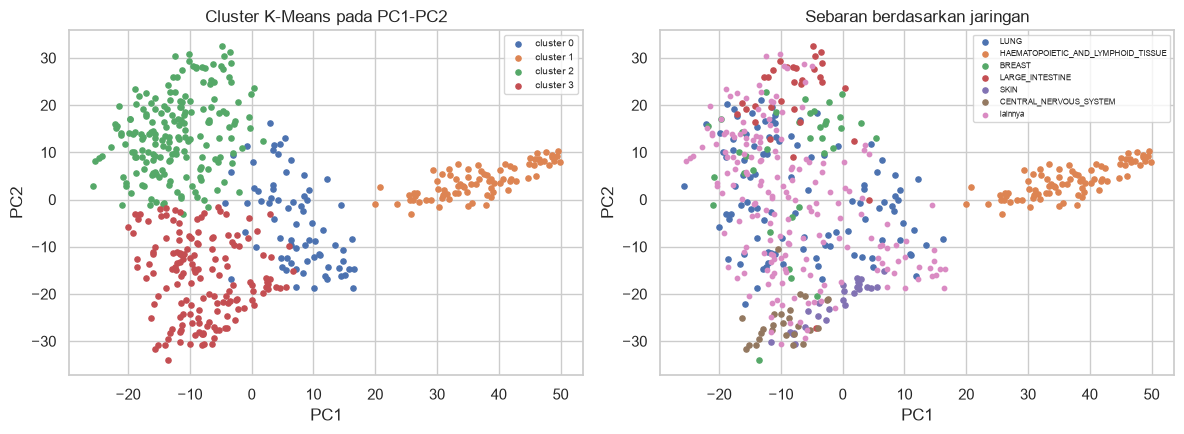

In [69]:
# Visualisasi cluster dan jaringan pada dua komponen utama pertama.
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for c in range(K_BASELINE):
    ax[0].scatter(P_dev[lab_dev == c, 0], P_dev[lab_dev == c, 1], s=14, label=f"cluster {c}")
ax[0].set_title("Cluster K-Means pada PC1-PC2")
ax[0].set_xlabel("PC1"); ax[0].set_ylabel("PC2"); ax[0].legend(fontsize=7)

besar = pd.Series(jar_asli).value_counts().head(6).index
for j in besar:
    m = jar_asli == j
    ax[1].scatter(P_dev[m, 0], P_dev[m, 1], s=14, label=j)
ax[1].scatter(P_dev[~np.isin(jar_asli, besar), 0], P_dev[~np.isin(jar_asli, besar), 1],
              s=10, label="lainnya")
ax[1].set_title("Sebaran berdasarkan jaringan")
ax[1].set_xlabel("PC1"); ax[1].set_ylabel("PC2"); ax[1].legend(fontsize=6)
plt.tight_layout(); plt.show()


In [70]:
# Perbedaan LN_IC50 antar-cluster untuk setiap DRUG_ID.
# Analisis ini hanya memakai development set; DRUG_ID berbeda tidak digabung.
resp_dev = respons_cv[respons_cv.COSMIC_ID.isin(ids[dev])].merge(
    pd.DataFrame({"COSMIC_ID": ids[dev], "cluster": lab_dev,
                  "hemato": metadata_cv.set_index("COSMIC_ID").loc[ids[dev], "hemato"].to_numpy()}),
    on="COSMIC_ID", how="inner", validate="many_to_one")

def uji_obat(data, nama):
    hasil = []
    for did, g in data.groupby("DRUG_ID"):
        kelompok = [x.LN_IC50.dropna().to_numpy() for _, x in g.groupby("cluster")]
        kelompok = [x for x in kelompok if len(x) >= 10]
        if len(kelompok) < 2:
            continue
        H, p = kruskal(*kelompok)
        n, k = sum(map(len, kelompok)), len(kelompok)
        hasil.append({"DRUG_ID": did, "obat": g.DRUG_NAME.iloc[0], "n_sel": n, "p": p,
                      "ukuran_efek_epsilon2": max(0, (H - k + 1) / (n - k))})
    D = pd.DataFrame(hasil)
    if D.empty:
        print(f"{nama}: tidak ada obat yang memenuhi syarat minimal 10 sel pada dua cluster.")
        return D
    D["fdr"] = false_discovery_control(D.p, method="bh")
    print(f"{nama}: {len(D)} obat diuji | FDR < 0,05: {(D.fdr < 0.05).sum()} | median ukuran efek = {D['ukuran_efek_epsilon2'].median():.3f}")
    return D

D_semua = uji_obat(resp_dev, "Semua jaringan")
D_padat = uji_obat(resp_dev[~resp_dev.hemato], "Jaringan non-hematopoietik")
if not D_padat.empty:
    display(D_padat.sort_values("ukuran_efek_epsilon2", ascending=False).head(10).round(4))


Semua jaringan: 295 obat diuji | FDR < 0,05: 293 | median ukuran efek = 0.214
Jaringan non-hematopoietik: 295 obat diuji | FDR < 0,05: 240 | median ukuran efek = 0.047


,DRUG_ID,obat,n_sel,p,ukuran_efek_epsilon2,fdr
106,1549,Sapitinib,411,0.0,0.1818,0.0000
17,1021,Axitinib,409,0.0,0.1795,0.0000
65,1096,Tozasertib,104,0.0,0.1791,0.0001
207,1845,Schweinfurthin A,318,0.0,0.1688,0.0000
166,1782,GSK2830371A,318,0.0,0.1610,0.0000
174,1804,Acetalax,318,0.0,0.1609,0.0000
173,1803,Acetalax,318,0.0,0.1559,0.0000
218,1909,Venetoclax,409,0.0,0.1517,0.0000
153,1720,AZD5991,316,0.0,0.1395,0.0000
194,1829,667880,318,0.0,0.1384,0.0000


# Pertemuan 6: Baseline final dan evaluasi pada test set


## 3. Baseline Clustering: K-Means

Konfigurasi baseline (`N_PC_BASELINE` dan `K_BASELINE`) ditetapkan dari validasi silang pada development set di Pertemuan 5. Setelah konfigurasi dipilih, preprocessing, PCA, dan K-Means di-*fit* ulang menggunakan seluruh development set. Test set hanya ditransformasi dan diprediksi, tanpa ikut menentukan parameter.


In [71]:
# Fit pipeline final hanya pada development set.
transform_final = Transformasi(N_GEN).fit(X[dev])
Z_dev_final = transform_final.transform(X[dev])
Z_test_final = transform_final.transform(X[test])

pca_final = PCA(n_components=50, random_state=SEED).fit(Z_dev_final)
P_dev_final = pca_final.transform(Z_dev_final)[:, :N_PC_BASELINE]
P_test_final = pca_final.transform(Z_test_final)[:, :N_PC_BASELINE]

kmeans_final = KMeans(n_clusters=K_BASELINE, n_init=10, random_state=SEED).fit(P_dev_final)
label_dev_final = kmeans_final.labels_
label_test = kmeans_final.predict(P_test_final)

print("Konfigurasi baseline: K-Means | K =", K_BASELINE, "| PC =", N_PC_BASELINE)
print("Development:", P_dev_final.shape, "| Test:", P_test_final.shape)
print("Test set diprediksi tanpa melakukan fit ulang:", len(label_test), "cell line")


Konfigurasi baseline: K-Means | K = 4 | PC = 20
Development: (496, 20) | Test: (125, 20)
Test set diprediksi tanpa melakukan fit ulang: 125 cell line


In [72]:
# Evaluasi test set: metrik internal dan kesesuaian dengan jaringan (bukan target pelatihan).
y_test = metadata_cv["tissue_ccle"].to_numpy()[test]
jumlah_cluster_test = np.unique(label_test).size
hasil_test = {
    "jumlah_cluster_test": jumlah_cluster_test,
    "silhouette_test": silhouette_score(P_test_final, label_test)
        if 1 < jumlah_cluster_test < len(label_test) else np.nan,
    "davies_bouldin_test": davies_bouldin_score(P_test_final, label_test)
        if 1 < jumlah_cluster_test < len(label_test) else np.nan,
    "ARI_vs_tissue_test": adjusted_rand_score(y_test, label_test),
    "NMI_vs_tissue_test": normalized_mutual_info_score(y_test, label_test),
}
display(pd.Series(hasil_test, name="nilai").to_frame().round(3))
print("Ukuran cluster pada test set:")
display(pd.Series(label_test).value_counts().sort_index().rename_axis("cluster").to_frame("jumlah_cell_line"))


,nilai
jumlah_cluster_test,4.000
silhouette_test,0.302
davies_bouldin_test,1.250
ARI_vs_tissue_test,0.206
NMI_vs_tissue_test,0.433


Ukuran cluster pada test set:


,jumlah_cell_line
cluster,
0,21
1,21
2,41
3,42


## 4. Peran PCA: Varians yang Dipertahankan

PCA dipelajari hanya dari development set. Tabel berikut menunjukkan proporsi varians yang dijelaskan setiap komponen dan varians kumulatifnya.


In [73]:
evr = pca_final.explained_variance_ratio_
tab_ev = pd.DataFrame({"varians_per_PC_%": evr * 100,
                       "varians_kumulatif_%": np.cumsum(evr) * 100},
                      index=pd.RangeIndex(1, len(evr) + 1, name="PC"))
display(tab_ev.loc[[i for i in [1, 2, 3, 4, 5, 10, 15, 20, 30, 50] if i <= len(tab_ev)]].round(2))
print(f"Fitur awal: {N_GEN} gen | PC baseline: {N_PC_BASELINE} | varians kumulatif: {np.sum(evr[:N_PC_BASELINE])*100:.2f}%")


,varians_per_PC_%,varians_kumulatif_%
PC,,
1,17.31,17.31
2,11.32,28.63
3,6.58,35.21
4,2.84,38.05
5,2.21,40.26
10,1.46,48.97
15,0.82,53.84
20,0.63,57.34
30,0.42,62.29


Fitur awal: 2000 gen | PC baseline: 20 | varians kumulatif: 57.34%


In [74]:
# Perbandingan jumlah PC pada development set menggunakan protokol CV yang sama.
baris = []
for npc in [5, 10, 20, 50, None]:
    r = jalankan_cv("kmeans", K_BASELINE, npc)
    baris.append({"jumlah_PC": "tanpa PCA" if npc is None else npc,
                  "silhouette": mean_sd(r, "sil"),
                  "konsistensi_ARI": mean_sd(r, "ari_ref"),
                  "ARI_vs_jaringan": mean_sd(r, "ari_jaringan"),
                  "NMI_vs_jaringan": mean_sd(r, "nmi_jaringan")})
tab_pca = pd.DataFrame(baris).set_index("jumlah_PC")
display(tab_pca)


,silhouette,konsistensi_ARI,ARI_vs_jaringan,NMI_vs_jaringan
jumlah_PC,,,,
5,0.429 ± 0.033,0.975 ± 0.028,0.183 ± 0.014,0.448 ± 0.021
10,0.339 ± 0.027,0.993 ± 0.015,0.185 ± 0.015,0.451 ± 0.020
20,0.282 ± 0.023,0.981 ± 0.032,0.186 ± 0.014,0.450 ± 0.022
50,0.243 ± 0.019,0.982 ± 0.026,0.185 ± 0.015,0.451 ± 0.020
tanpa PCA,0.140 ± 0.013,0.982 ± 0.018,0.185 ± 0.015,0.451 ± 0.020


## 5. Perbandingan Algoritma Clustering

Empat pendekatan dibandingkan pada development set dengan jumlah PC dan jumlah cluster yang sama: K-Means (baseline), Hierarchical Ward, DBSCAN, dan Gaussian Mixture Model (GMM). DBSCAN tidak memakai jumlah cluster, jadi jumlah cluster dan persen *noise*-nya ikut ditampilkan. Test set tidak digunakan untuk memilih algoritma.


In [75]:
hasil_model = []
for nama, metode in [("K-Means (baseline)", "kmeans"),
                     ("Agglomerative Ward", "ward"),
                     ("DBSCAN", "dbscan"),
                     ("Gaussian Mixture Model (GMM)", "gmm")]:
    r = jalankan_cv(metode, K_BASELINE, N_PC_BASELINE)
    hasil_model.append({"algoritma": nama, 
                        "silhouette": mean_sd(r, "sil"),
                        "davies_bouldin": mean_sd(r, "db"),
                        "konsistensi_ARI": mean_sd(r, "ari_ref"),
                        "ARI_vs_jaringan": mean_sd(r, "ari_jaringan"),
                        "NMI_vs_jaringan": mean_sd(r, "nmi_jaringan"),
                        "jumlah_cluster": f"{r.n_klaster.mean():.1f}",
                        "noise_%": f"{r.pct_noise.mean():.1f}",}
    )
tab_model = pd.DataFrame(hasil_model).set_index("algoritma")
display(tab_model)


,silhouette,davies_bouldin,konsistensi_ARI,ARI_vs_jaringan,NMI_vs_jaringan,jumlah_cluster,noise_%
algoritma,,,,,,,
K-Means (baseline),0.282 ± 0.023,1.294 ± 0.073,0.981 ± 0.032,0.186 ± 0.014,0.450 ± 0.022,4.0,0.0
Agglomerative Ward,0.278 ± 0.024,1.310 ± 0.118,0.676 ± 0.068,0.177 ± 0.018,0.442 ± 0.014,4.0,0.0
DBSCAN,0.337 ± 0.024,1.054 ± 0.070,0.952 ± 0.033,0.074 ± 0.004,0.292 ± 0.006,2.0,0.0
Gaussian Mixture Model (GMM),0.270 ± 0.041,1.322 ± 0.120,0.756 ± 0.149,0.166 ± 0.052,0.438 ± 0.040,4.0,0.0


**Ringkasan perbandingan algoritma:** hasilnya sejalan dengan Pertemuan 5. K-Means paling stabil (konsistensi ARI 0,981) dan paling sesuai dengan jaringan (NMI 0,450). Ward (0,676) dan GMM (0,756) kurang stabil. DBSCAN hanya menemukan 2 cluster (NMI 0,292), jadi tidak bisa memisahkan jaringan padat. **K-Means dipertahankan sebagai model final**, dan test set hanya dipakai untuk model itu (bagian 3).


## 6. Profil Cluster Baseline

Profil berikut menggunakan label cluster dari model yang di-*fit* pada development set. Label jaringan dan respons obat hanya digunakan untuk interpretasi.


In [76]:
# Ringkasan ukuran dan jaringan dominan setiap cluster pada development set.
profil_final = metadata_cv.iloc[dev][["tissue_ccle", "tissue_major", "hemato"]].copy()
profil_final["cluster"] = label_dev_final
ringkasan_cluster = []
for c, g in profil_final.groupby("cluster"):
    vc = g["tissue_ccle"].value_counts()
    ringkasan_cluster.append({"cluster": c, "jumlah": len(g), "persen": round(len(g)/len(profil_final)*100, 1),
                              "jaringan_dominan": vc.index[0],
                              "proporsi_jaringan_dominan_%": round(vc.iloc[0]/len(g)*100, 1),
                              "jumlah_jaringan": vc.size})
display(pd.DataFrame(ringkasan_cluster).sort_values("cluster"))


,cluster,jumlah,persen,jaringan_dominan,proporsi_jaringan_dominan_%,jumlah_jaringan
0,0,72,14.5,LUNG,44.4,14
1,1,82,16.5,HAEMATOPOIETIC_AND_LYMPHOID_TISSUE,100.0,1
2,2,187,37.7,LUNG,21.4,14
3,3,155,31.2,LUNG,21.3,19


In [77]:
# Respons obat per cluster pada development set; pengujian dipisahkan berdasarkan DRUG_ID.
resp_dev_final = respons_cv[respons_cv.COSMIC_ID.isin(ids[dev])].merge(
    pd.DataFrame({"COSMIC_ID": ids[dev], "cluster": label_dev_final}),
    on="COSMIC_ID", how="inner", validate="many_to_one")
if not D_semua.empty:
    print("Jumlah DRUG_ID yang diuji pada analisis Pertemuan 5:", D_semua.DRUG_ID.nunique())
print("Data respons pada development set:", resp_dev_final.shape,
      "| jumlah DRUG_ID:", resp_dev_final.DRUG_ID.nunique())


Jumlah DRUG_ID yang diuji pada analisis Pertemuan 5: 295
Data respons pada development set: (125024, 10) | jumlah DRUG_ID: 295


## 7. Kestabilan dan Sensitivitas

Kestabilan diperiksa melalui variasi pembagian fold dan perubahan jumlah gen. Nilai ARI pada bagian ini menunjukkan konsistensi hasil pengelompokan terhadap partisi acuan, bukan akurasi prediksi label kanker.


In [78]:
# Rekap sensitivitas jumlah gen dan pengulangan pembagian fold.
# tab_sens berasal dari Pertemuan 5; rep mengulang CV dengan seed pembagian berbeda.
rep = []
for seed_fold in [1, 2, 3, 4, 5]:
    r = jalankan_cv("kmeans", K_BASELINE, N_PC_BASELINE, seed_lipatan=seed_fold)
    rep.append({"seed_fold": seed_fold, "silhouette_mean": r.sil.mean(),
                "ARI_konsistensi_mean": r.ari_ref.mean(), "ARI_konsistensi_min": r.ari_ref.min()})
tab_seed = pd.DataFrame(rep).set_index("seed_fold")
print("Sensitivitas jumlah gen:")
display(tab_sens)
print("Sensitivitas pembagian fold:")
display(tab_seed.round(3))


Sensitivitas jumlah gen:


,Silhouette,Konsistensi ARI,ARI vs jaringan
N_GEN,,,
1000,0.294 ± 0.024,0.975 ± 0.028,0.185 ± 0.016
2000,0.282 ± 0.023,0.981 ± 0.032,0.186 ± 0.014
5000,0.261 ± 0.019,0.937 ± 0.012,0.177 ± 0.008


Sensitivitas pembagian fold:


,silhouette_mean,ARI_konsistensi_mean,ARI_konsistensi_min
seed_fold,,,
1,0.282,0.994,0.968
2,0.280,0.996,0.978
3,0.282,0.987,0.958
4,0.281,0.983,0.950
5,0.279,0.984,0.967


## 8. Tabel Ringkasan Hasil

Ringkasan memisahkan hasil validasi silang pada development set dan evaluasi akhir pada test set yang sebelumnya dikunci.


In [79]:
r_baseline_final = jalankan_cv("kmeans", K_BASELINE, N_PC_BASELINE)
ringkasan_akhir = pd.DataFrame([
    {"tahap": "CV development", "metode": f"K-Means K={K_BASELINE}, PCA {N_PC_BASELINE}",
     "silhouette": r_baseline_final.sil.mean(),
     "ARI_vs_tissue": r_baseline_final.ari_jaringan.mean(),
     "NMI_vs_tissue": r_baseline_final.nmi_jaringan.mean()},
    {"tahap": "Test terkunci", "metode": f"K-Means K={K_BASELINE}, PCA {N_PC_BASELINE}",
     "silhouette": hasil_test["silhouette_test"],
     "ARI_vs_tissue": hasil_test["ARI_vs_tissue_test"],
     "NMI_vs_tissue": hasil_test["NMI_vs_tissue_test"]},
]).set_index("tahap")
display(ringkasan_akhir.round(3))

# Simpan hasil ringkasan jika diperlukan.
ringkasan_akhir.to_csv("ringkasan_evaluasi_pertemuan_6.csv")
tab_pca.to_csv("perbandingan_jumlah_pc.csv")
tab_model.to_csv("perbandingan_algoritma.csv")
print("Tabel hasil disimpan sebagai CSV di lingkungan notebook.")


,metode,silhouette,ARI_vs_tissue,NMI_vs_tissue
tahap,,,,
CV development,"K-Means K=4, PCA 20",0.282,0.186,0.450
Test terkunci,"K-Means K=4, PCA 20",0.302,0.206,0.433


Tabel hasil disimpan sebagai CSV di lingkungan notebook.
